In [1]:
import pandas as pd
import numpy as np
from cmdstanpy import CmdStanModel
import geopandas as gpd
from libpysal import weights
from sklearn.preprocessing import LabelEncoder
import networkx as nx
import re
import os
import pickle
from scipy.sparse import diags

/home/yuyue/stan_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
strat_frame = pd.read_csv("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/cleaned_sf.csv")

In [3]:
strat_frame

,Unnamed: 0,sex_idx,age_idx,eth_idx,income_idx,state_idx,vote_idx,education_idx,N_star.1,N_star.2,...,state_electoral.college,region,gender,ethnicity,age_bins,college_grad,hh_income,vote2020,vote2022,state_abbreviation_upper
0,0,2,1,4,1,1,1,1,11.20473,3.28863,...,Alaska,West,F,Asian,1.18-24,Does not have a College Degree,"1.[min, 25000)",stay home,D,AK
1,1,2,1,4,1,1,2,1,0.08251,0.83856,...,Alaska,West,F,Asian,1.18-24,Does not have a College Degree,"1.[min, 25000)",R,D,AK
2,2,2,1,4,1,1,3,1,1.58995,9.61664,...,Alaska,West,F,Asian,1.18-24,Does not have a College Degree,"1.[min, 25000)",D,D,AK
3,3,2,1,4,1,1,4,1,0.01103,0.04211,...,Alaska,West,F,Asian,1.18-24,Does not have a College Degree,"1.[min, 25000)",L,D,AK
4,4,2,1,4,1,1,6,1,0.09892,0.18006,...,Alaska,West,F,Asian,1.18-24,Does not have a College Degree,"1.[min, 25000)",OTHER,D,AK
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190839,190839,1,6,1,5,51,3,2,183.35671,191.99599,...,Wyoming,West,M,White,6.65+,Has a College Degree,"5.[100000, max]",D,D,WY
190840,190840,1,6,1,5,51,4,1,0.27655,0.20655,...,Wyoming,West,M,White,6.65+,Does not have a College Degree,"5.[100000, max]",L,D,WY
190841,190841,1,6,1,5,51,4,2,0.94979,0.07475,...,Wyoming,West,M,White,6.65+,Has a College Degree,"5.[100000, max]",L,D,WY
190842,190842,1,6,1,5,51,6,1,0.47236,0.38748,...,Wyoming,West,M,White,6.65+,Does not have a College Degree,"5.[100000, max]",OTHER,D,WY


In [4]:
strat_frame['N_star.median'].sum()

np.float64(10370279.246645)

In [5]:
strat_frame.columns.tolist()

['Unnamed: 0',
 'sex_idx',
 'age_idx',
 'eth_idx',
 'income_idx',
 'state_idx',
 'vote_idx',
 'education_idx',
 'N_star.1',
 'N_star.2',
 'N_star.3',
 'N_star.4',
 'N_star.5',
 'N_star.6',
 'N_star.7',
 'N_star.8',
 'N_star.9',
 'N_star.10',
 'N_star.11',
 'N_star.12',
 'N_star.13',
 'N_star.14',
 'N_star.15',
 'N_star.16',
 'N_star.17',
 'N_star.18',
 'N_star.19',
 'N_star.20',
 'N_star.21',
 'N_star.22',
 'N_star.23',
 'N_star.24',
 'N_star.25',
 'N_star.26',
 'N_star.27',
 'N_star.28',
 'N_star.29',
 'N_star.30',
 'N_star.31',
 'N_star.32',
 'N_star.33',
 'N_star.34',
 'N_star.35',
 'N_star.36',
 'N_star.37',
 'N_star.38',
 'N_star.39',
 'N_star.40',
 'N_star.41',
 'N_star.42',
 'N_star.43',
 'N_star.44',
 'N_star.45',
 'N_star.46',
 'N_star.47',
 'N_star.48',
 'N_star.49',
 'N_star.50',
 'N_star.51',
 'N_star.52',
 'N_star.53',
 'N_star.54',
 'N_star.55',
 'N_star.56',
 'N_star.57',
 'N_star.58',
 'N_star.59',
 'N_star.60',
 'N_star.61',
 'N_star.62',
 'N_star.63',
 'N_star.64',
 '

In [6]:
df = pd.read_pickle('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/preprocessed_cleaned_all_result.pkl')

In [7]:
df

,id,time_window_start,tweets_struct,name,username,description,location,public_metrics.followers_count,profile_image_url,clean...pool,...,Belief_opinion_on_whether_the_tone_of_political_discourse_in_the_u_s_has_become_more_factbased_Symbol_num,Belief_opinion_on_the_statement_elected_officials_using_heated_or_aggressive_language_to_talk_about_certain_people_or_groups_makes_violence_against_those_groups_more_likely_Symbol_cat,Belief_opinion_on_the_statement_elected_officials_using_heated_or_aggressive_language_to_talk_about_certain_people_or_groups_makes_violence_against_those_groups_more_likely_Symbol_num,Demo_sex_idx,Demo_age_idx,Demo_ethnicity_idx,Demo_income_idx,Demo_education_idx,Demo_past_vote_idx,state_cleaned_idx
0,1081532502966239232,2023-11-05 00:00:00+00:00,[],caleb ❍,xxaleb,"i think a lot, listen to music. i’m fond of fl...",they/he ☆ 20,4426,https://pbs.twimg.com/profile_images/180336437...,trad,...,0,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1081532502966239232,2023-11-19 00:00:00+00:00,[],caleb ❍,xxaleb,"i think a lot, listen to music. i’m fond of fl...",they/he ☆ 20,4426,https://pbs.twimg.com/profile_images/180336437...,trad,...,0,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1081532502966239232,2023-12-03 00:00:00+00:00,[],caleb ❍,xxaleb,"i think a lot, listen to music. i’m fond of fl...",they/he ☆ 20,4426,https://pbs.twimg.com/profile_images/180336437...,trad,...,0,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1081532502966239232,2023-12-17 00:00:00+00:00,[],caleb ❍,xxaleb,"i think a lot, listen to music. i’m fond of fl...",they/he ☆ 20,4426,https://pbs.twimg.com/profile_images/180336437...,trad,...,0,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1081532502966239232,2023-12-31 00:00:00+00:00,[],caleb ❍,xxaleb,"i think a lot, listen to music. i’m fond of fl...",they/he ☆ 20,4426,https://pbs.twimg.com/profile_images/180336437...,trad,...,0,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23984,142827500,2024-08-11 00:00:00+00:00,"['12 weeks to election', {'text': '@maxies_bac...",Andy,ndrwwwww,architectural designer \n\nhe/him,"Chicago, IL",734,https://pbs.twimg.com/profile_images/137092184...,guns,...,2,dib1,1,1.0,2.0,1.0,4.0,2.0,3.0,15.0
23985,142827500,2024-08-25 00:00:00+00:00,"['10 weeks to election', {'text': '@foldyrhand...",Andy,ndrwwwww,architectural designer \n\nhe/him,"Chicago, IL",734,https://pbs.twimg.com/profile_images/137092184...,guns,...,2,dib1,1,1.0,2.0,1.0,3.0,2.0,3.0,15.0
23987,142827500,2024-09-22 00:00:00+00:00,"['6 weeks to election', {'text': '@kevin__fm S...",Andy,ndrwwwww,architectural designer \n\nhe/him,"Chicago, IL",734,https://pbs.twimg.com/profile_images/137092184...,guns,...,2,dib1,1,1.0,2.0,1.0,3.0,2.0,3.0,15.0
23988,142827500,2024-10-06 00:00:00+00:00,"['4 weeks to election', {'text': '@cherryrepre...",Andy,ndrwwwww,architectural designer \n\nhe/him,"Chicago, IL",734,https://pbs.twimg.com/profile_images/137092184...,guns,...,2,dib1,1,1.0,2.0,1.0,3.0,2.0,1.0,15.0


In [5]:
print(df.columns.to_list())

['id', 'time_window_start', 'tweets_struct', 'name', 'username', 'description', 'location', 'public_metrics.followers_count', 'profile_image_url', 'clean...pool', 'is_empty_window', 'window_weeks_to_election', 'profile_image_description', 'profile_image_main_info', 'Model', 'Belief_Raw', 'Belief_Cleaned', 'Demo_Raw', 'Demo_Cleaned', 'Belief_opinion_on_the_number_of_immigrants_in_america_Category', 'Belief_opinion_on_the_number_of_immigrants_in_america_Explanation', 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol', 'Belief_opinion_on_the_number_of_immigrants_in_america_Speculation', 'Belief_opinion_on_the_statement_immigrants_increase_crime_rates_Category', 'Belief_opinion_on_the_statement_immigrants_increase_crime_rates_Explanation', 'Belief_opinion_on_the_statement_immigrants_increase_crime_rates_Symbol', 'Belief_opinion_on_the_statement_immigrants_increase_crime_rates_Speculation', 'Belief_opinion_on_the_statement_immigrants_take_jobs_away_from_people_who_were_born_in_t

In [8]:
belief_col = "Belief_opinion_on_the_number_of_immigrants_in_america_Symbol"

In [7]:
predictor_cols = [
    "Demo_sex_Symbol",
    "Demo_age_Symbol",
    "Demo_ethnicity_Symbol",
    "Demo_income_Symbol",
    "Demo_education_Symbol",
    "Demo_past_vote_Symbol",
    "state_cleaned"
]
df = df.dropna(subset=[belief_col] + predictor_cols)

In [8]:
df

,id,time_window_start,tweets_struct,name,username,description,location,public_metrics.followers_count,profile_image_url,clean...pool,...,Belief_opinion_on_whether_the_tone_of_political_discourse_in_the_u_s_has_become_more_factbased_Symbol_num,Belief_opinion_on_the_statement_elected_officials_using_heated_or_aggressive_language_to_talk_about_certain_people_or_groups_makes_violence_against_those_groups_more_likely_Symbol_cat,Belief_opinion_on_the_statement_elected_officials_using_heated_or_aggressive_language_to_talk_about_certain_people_or_groups_makes_violence_against_those_groups_more_likely_Symbol_num,Demo_sex_idx,Demo_age_idx,Demo_ethnicity_idx,Demo_income_idx,Demo_education_idx,Demo_past_vote_idx,state_cleaned_idx
40,1542629834953719810,2024-05-19 00:00:00+00:00,"['24 weeks to election', {'text': '@The_Trump_...",Ashley Diller,Badash1821,A mom of 5 with common sense! Hates being lie...,"Ohio, USA",625,https://pbs.twimg.com/profile_images/169368304...,radical,...,2,dib1,1,2.0,3.0,1.0,3.0,1.0,2.0,36.0
41,1542629834953719810,2024-06-16 00:00:00+00:00,"['20 weeks to election', {'text': '🤣 https://t...",Ashley Diller,Badash1821,A mom of 5 with common sense! Hates being lie...,"Ohio, USA",625,https://pbs.twimg.com/profile_images/169368304...,radical,...,2,dib1,1,2.0,3.0,1.0,3.0,1.0,2.0,36.0
43,1542629834953719810,2024-07-14 00:00:00+00:00,"['16 weeks to election', {'text': '🤣🤣🤣 https:/...",Ashley Diller,Badash1821,A mom of 5 with common sense! Hates being lie...,"Ohio, USA",625,https://pbs.twimg.com/profile_images/169368304...,radical,...,2,dib3,3,2.0,3.0,1.0,3.0,1.0,2.0,36.0
44,1542629834953719810,2024-07-28 00:00:00+00:00,"['14 weeks to election', {'text': '@victormarx...",Ashley Diller,Badash1821,A mom of 5 with common sense! Hates being lie...,"Ohio, USA",625,https://pbs.twimg.com/profile_images/169368304...,radical,...,2,dib1,1,2.0,3.0,1.0,2.0,1.0,3.0,36.0
45,1542629834953719810,2024-08-11 00:00:00+00:00,"['12 weeks to election', {'text': '🤣🥰 https://...",Ashley Diller,Badash1821,A mom of 5 with common sense! Hates being lie...,"Ohio, USA",625,https://pbs.twimg.com/profile_images/169368304...,radical,...,2,dib1,1,2.0,3.0,1.0,3.0,1.0,2.0,36.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23984,142827500,2024-08-11 00:00:00+00:00,"['12 weeks to election', {'text': '@maxies_bac...",Andy,ndrwwwww,architectural designer \n\nhe/him,"Chicago, IL",734,https://pbs.twimg.com/profile_images/137092184...,guns,...,2,dib1,1,1.0,2.0,1.0,4.0,2.0,3.0,15.0
23985,142827500,2024-08-25 00:00:00+00:00,"['10 weeks to election', {'text': '@foldyrhand...",Andy,ndrwwwww,architectural designer \n\nhe/him,"Chicago, IL",734,https://pbs.twimg.com/profile_images/137092184...,guns,...,2,dib1,1,1.0,2.0,1.0,3.0,2.0,3.0,15.0
23987,142827500,2024-09-22 00:00:00+00:00,"['6 weeks to election', {'text': '@kevin__fm S...",Andy,ndrwwwww,architectural designer \n\nhe/him,"Chicago, IL",734,https://pbs.twimg.com/profile_images/137092184...,guns,...,2,dib1,1,1.0,2.0,1.0,3.0,2.0,3.0,15.0
23988,142827500,2024-10-06 00:00:00+00:00,"['4 weeks to election', {'text': '@cherryrepre...",Andy,ndrwwwww,architectural designer \n\nhe/him,"Chicago, IL",734,https://pbs.twimg.com/profile_images/137092184...,guns,...,2,dib1,1,1.0,2.0,1.0,3.0,2.0,1.0,15.0


In [10]:
# prepare spatial structure for ICAR
def edges_from_adjacency(W):
    all_edges = []
    n = W.shape[0]
    
    for i in range(n):
        neighbors = np.where(W[i, :] != 0)[0]
        for j in neighbors:
            if i < j:  
                all_edges.append({
                    'node1': i + 1,  
                    'node2': j + 1,
                    'weight': W[i, j]
                })
    
    return pd.DataFrame(all_edges)


def scale_c(C):
    N = C.shape[0]
    
    if hasattr(C, 'toarray'):
        C = C.toarray()
    C = np.asarray(C)
    
    row_sums = C.sum(axis=1).ravel()
    Q = diags(row_sums) - C
    
    Q_dense = Q.toarray() if hasattr(Q, 'toarray') else np.asarray(Q)
    max_diag = np.max(np.diag(Q_dense))
    jitter = max_diag * np.sqrt(np.finfo(float).eps)
    Q_pert = Q_dense + np.diag(np.ones(N) * jitter)
    
    Q_inv = np.linalg.pinv(Q_pert)
    
    variances = np.diag(Q_inv)
    scaling_factor = np.exp(np.mean(np.log(variances)))
    
    return scaling_factor


def prep_icar_data_from_weights(w, N_states):
    C = np.zeros((N_states, N_states))
    for i in range(N_states):
        for j in w.neighbors[i]:
            C[i, j] = 1

    E = edges_from_adjacency(C)
    
    G = nx.Graph()
    G.add_nodes_from(range(N_states))
    for _, row in E.iterrows():
        G.add_edge(int(row['node1']) - 1, int(row['node2']) - 1)
    
    components = list(nx.connected_components(G))
    k = len(components)
    
    comp_id = np.zeros(N_states, dtype=int)
    for idx, component in enumerate(components):
        for node in component:
            comp_id[int(node)] = idx
    
    group_size = np.array([len(comp) for comp in components])
    
    group_idx = comp_id + 1

    
    return {
        'k': int(k),
        'group_size': group_size.tolist(),
        'N_edges': len(E),
        'node1': E['node1'].values.tolist(),
        'node2': E['node2'].values.tolist(),
        'group_idx': group_idx.tolist()
    }


def moran_coefficient(x, W, warn=True):
    row_sums = W.sum(axis=1)
    zero_idx = np.where(row_sums == 0)[0]
    
    if len(zero_idx) > 0:
        if warn:
            print(f"{len(zero_idx)} observations with no neighbors. Dropping from calculation.")
        keep_idx = row_sums > 0
        x = x[keep_idx]
        W = W[np.ix_(keep_idx, keep_idx)]
    
    n = len(x)
    xbar = np.mean(x)
    z = x - xbar
    z_tilde = W @ z
    A = np.sum(W)
    mc = (n / A) * (z @ z_tilde) / (z @ z)
    
    return np.round(mc, 3)

# Build spatial structure
shp = gpd.read_file("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/tl_2025_us_state/tl_2025_us_state.shp")
shp["STATE"] = shp["STUSPS"].str.upper()

shp = shp[~shp["STATE"].isin(["PR", "GU", "VI", "MP", "AS"])]

shp = shp.sort_values("STATE").reset_index(drop=True)

state_order = shp["STATE"].tolist()
N_states = len(state_order)

print(f"Shapefile states: {N_states}")

w = weights.Queen.from_dataframe(shp)

icar_data = prep_icar_data_from_weights(w, N_states)

print(f"\nICAR structure:")
print(f"  Connected components: {icar_data['k']}")
print(f"  Component sizes: {icar_data['group_size']}")
print(f"  Number of edges: {icar_data['N_edges']}")



Shapefile states: 51


/tmp/ipykernel_685553/4196857512.py:111: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = weights.Queen.from_dataframe(shp)



ICAR structure:
  Connected components: 3
  Component sizes: [1, 49, 1]
  Number of edges: 112


/home/yuyue/stan_env/lib/python3.12/site-packages/libpysal/weights/contiguity.py:347: UserWarning: The weights matrix is not fully connected: 
 There are 3 disconnected components.
 There are 2 islands with ids: 0, 11.
  W.__init__(self, neighbors, ids=ids, **kw)


In [11]:
shp.head()

,REGION,DIVISION,STATEFP,STATENS,GEOID,GEOIDFQ,STUSPS,NAME,LSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry,STATE
0,4,9,02,01785533,02,0400000US02,AK,Alaska,00,G4000,A,1479893380150,244326118163,+63.3473560,-152.8397334,"MULTIPOLYGON (((-167.55823 60.22436, -167.5567...",AK
1,3,6,01,01779775,01,0400000US01,AL,Alabama,00,G4000,A,131186429591,4580729056,+32.7395785,-086.8434469,"POLYGON ((-85.12733 31.76256, -85.12753 31.762...",AL
2,3,7,05,00068085,05,0400000US05,AR,Arkansas,00,G4000,A,134658642291,3122591253,+34.8955256,-092.4446262,"POLYGON ((-90.95577 34.11871, -90.95451 34.117...",AR
3,4,8,04,01779777,04,0400000US04,AZ,Arizona,00,G4000,A,294366238828,853868947,+34.2039362,-111.6063449,"POLYGON ((-110.75069 37.00301, -110.74193 37.0...",AZ
4,4,9,06,01779778,06,0400000US06,CA,California,00,G4000,A,403676564152,20288505023,+37.1551773,-119.5434183,"MULTIPOLYGON (((-119.99987 41.18397, -119.9998...",CA


In [13]:
# state level fixed effects
LP_cols = [
    'LP_pct.2020.votes.R', 'LP_pct.2020.votes.stay.home'
]
LP_state = (
    strat_frame
    .assign(STATE=strat_frame["state_abbreviation"].str.upper())
    .groupby("STATE")[LP_cols]
    .mean()
)
LP_state = LP_state.reindex(state_order)

LP_mat = LP_state.values
P = LP_mat.shape[1]
print(LP_mat.shape)

(51, 2)


In [14]:
print(LP_mat)

[[ 0.3032589  -0.15494699]
 [ 1.06868261  0.92695691]
 [ 1.09897892  1.87393581]
 [-0.01104556 -0.13549883]
 [-1.23719282 -0.06126084]
 [-0.63112784 -1.72932917]
 [-0.83225137 -0.36399364]
 [-3.64396112  0.30521813]
 [-0.78334293 -0.39551991]
 [ 0.16901134 -0.80350951]
 [ 0.00405679 -0.12421476]
 [-1.26764912  1.97166449]
 [ 0.30051743 -0.98120931]
 [ 1.2189566   0.05901784]
 [-0.71855639  0.2087094 ]
 [ 0.65175111  1.08771718]
 [ 0.58446232  0.28206992]
 [ 1.07325333  0.47984469]
 [ 0.77155319  0.61767264]
 [-1.43794678 -0.65951938]
 [-1.41779837 -0.34927793]
 [-0.41779583 -1.474638  ]
 [-0.11245498 -1.00240798]
 [-0.32484046 -2.09808463]
 [ 0.63331954  0.20469241]
 [ 0.70016347  1.25593282]
 [ 0.64320622 -0.79548343]
 [ 0.06204364 -0.91829113]
 [ 1.32517512  0.71970753]
 [ 0.83397673 -0.2725791 ]
 [-0.31890604 -1.20076828]
 [-0.64840276 -0.5917758 ]
 [-0.47364589  1.10262997]
 [-0.1266878   0.19441404]
 [-0.97586033  1.07755046]
 [ 0.33971872  0.12281927]
 [ 1.34674554  2.06296573]
 

In [15]:
LP_df = pd.DataFrame(
    LP_mat,
    index=[s.upper() for s in state_order],
    columns=LP_cols
)

LP_df

,LP_pct.2020.votes.R,LP_pct.2020.votes.stay.home
AK,0.303259,-0.154947
AL,1.068683,0.926957
AR,1.098979,1.873936
AZ,-0.011046,-0.135499
CA,-1.237193,-0.061261
CO,-0.631128,-1.729329
CT,-0.832251,-0.363994
DC,-3.643961,0.305218
DE,-0.783343,-0.395520
FL,0.169011,-0.803510


In [16]:
print(df["Demo_age_idx"].unique())

[3. 4. 5. 2. 6. 1.]


In [ ]:
# Stan code (update: with state-level effect and vote interaction)
stan_code = '''
functions {
  real icar_normal_lpdf(vector phi, int N_edges,
                        array[] int node1, array[] int node2) {
    return -0.5 * dot_self(phi[node1] - phi[node2]);
  }
}

data {
  int<lower=1> N;                   
  int<lower=2> K;                 
  array[N] int<lower=1, upper=K> y;

  int<lower=1> J_sex;
  int<lower=1> J_age;
  int<lower=1> J_eth;
  int<lower=1> J_income;
  int<lower=1> J_education;
  int<lower=1> J_vote;
  int<lower=1> N_states;

  array[N] int<lower=1, upper=J_sex> sex_idx;
  array[N] int<lower=1, upper=J_age> age_idx;
  array[N] int<lower=1, upper=J_eth> eth_idx;
  array[N] int<lower=1, upper=J_income> income_idx;
  array[N] int<lower=1, upper=J_education> education_idx;
  array[N] int<lower=1, upper=J_vote> vote_idx;
  array[N] int<lower=1, upper=N_states> state_idx;

  // ICAR structure
  int<lower=1> N_edges;
  array[N_edges] int node1;
  array[N_edges] int node2;

  int<lower=1> k;                           // number of connected components
  array[k] int group_size;                  // size of each connected component
  array[N_states] int group_idx;           // component assignment for each state

  // state level fixed effects
  int<lower=1> P;                           // number of state-level predictors
  matrix[N_states, P] LP;                  // state-level predictor matrix
}

parameters {
  ordered[K-1] kappa;

  sum_to_zero_vector[J_sex] eta_sex; // use build in sum_to_zero_vector instead of hard coding it
  sum_to_zero_vector[J_age] eta_age;             
  sum_to_zero_vector[J_eth] eta_eth;
  sum_to_zero_vector[J_income] eta_income; 
  sum_to_zero_vector[J_education] eta_education;     
  sum_to_zero_vector[J_vote] eta_vote;
  vector[N_states] eta_state_raw;
  vector[P] beta_LP;

  real<lower=0> sigma_sex;
  real<lower=0> sigma_age;
  real<lower=0> sigma_eth;
  real<lower=0> sigma_income;
  real<lower=0> sigma_education;
  real<lower=0> sigma_vote;
  real<lower=0> sigma_state;

  matrix[J_vote, P] beta_LP_vote; // interaction effects between vote and state-level predictors (N x P)
}

transformed parameters {
  vector[J_sex] eta_sex_star = eta_sex * sigma_sex ;
  vector[J_age] eta_age_star = eta_age * sigma_age;
  vector[J_eth] eta_eth_star = eta_eth * sigma_eth ;
  vector[J_income] eta_income_star = eta_income * sigma_income;
  vector[J_education] eta_education_star = eta_education * sigma_education;
  vector[J_vote] eta_vote_star = eta_vote * sigma_vote;
  vector[N_states] mu_state_LP = LP * beta_LP; 
  vector[N_states] eta_state = sigma_state * eta_state_raw;
  vector[N] mu_state_LP_vote = rows_dot_product(LP[state_idx], beta_LP_vote[vote_idx]);// double check if it needs to be transpose extract vote specific coefficients for each observation based on their vote_idx and state_idx
}

model {
  // Priors
  kappa ~ normal(0, 3);
  beta_LP ~ normal(0, 1);
  beta_LP_vote ~ normal(0, 1);
  
   // prior on the constrained vector (Stan handles the internal K-1 representation)
  eta_sex ~ normal(0, 1);
  eta_eth ~ normal(0, 1);
  eta_vote ~ normal(0, 1);
  eta_education ~ normal(0, 1);
  sigma_sex ~ normal(0, 1);
  sigma_age ~ normal(0, 1);
  sigma_eth ~ normal(0, 1);
  sigma_income ~ normal(0, 1);
  sigma_education ~ normal(0, 1);
  sigma_vote ~ normal(0, 1);
  sigma_state ~ normal(0, 1);

  for (i in 2:J_age) {
    eta_age[i] ~ normal(eta_age[i-1], 1);
  }
  for (i in 2:J_income) {
    eta_income[i] ~ normal(eta_income[i-1], 1);
  }

  // ICAR prior on raw spatial effects
  target += icar_normal_lpdf(eta_state_raw | N_edges, node1, node2);
  
  // Sum-to-zero constraint per connected component (island can have free prior)
  for (j in 1:k) {
  if (group_size[j] > 1) {
    // Soft sum-to-zero constraint for proper ICAR within this component
    real component_sum = 0;
    for (i in 1:N_states) {
      if (group_idx[i] == j) {
        component_sum += eta_state_raw[i];
      }
    }
    target += normal_lpdf(component_sum | 0, 0.001 * group_size[j]);
  } else {
    // Island component: give the singleton node a proper iid prior
    for (i in 1:N_states) {
      if (group_idx[i] == j) {
        eta_state_raw[i] ~ normal(0, 1);
      }
    }
  }
}

  // Ordered logistic
  for (i in 1:N) {
    real mu = eta_sex_star[sex_idx[i]]
              + eta_age_star[age_idx[i]]
              + eta_eth_star[eth_idx[i]]
              + eta_income_star[income_idx[i]]
              + eta_vote_star[vote_idx[i]]
              + eta_education_star[education_idx[i]]
              + eta_state[state_idx[i]]
              + mu_state_LP[state_idx[i]];
              + mu_state_LP_vote[i];
    y[i] ~ ordered_logistic(mu, kappa);
  }
}

generated quantities {
  vector[N] mu;
  vector[N] log_lik;
  
  for (i in 1:N) {
    mu[i] = eta_sex_star[sex_idx[i]]
            + eta_age_star[age_idx[i]]
            + eta_eth_star[eth_idx[i]]
            + eta_income_star[income_idx[i]]
            + eta_vote_star[vote_idx[i]]
            + eta_education_star[education_idx[i]]
            + eta_state[state_idx[i]]
            + mu_state_LP[state_idx[i]];
            + mu_state_LP_vote[i];
    log_lik[i] = ordered_logistic_lpmf(y[i] | mu[i], kappa);
  }
}
'''


# Compile and Sample

with open('mrp.stan', 'w') as f:
    f.write(stan_code)

model = CmdStanModel(stan_file='mrp.stan')


23:00:32 - cmdstanpy - INFO - compiling stan file /tmp/tmphux4xoko/tmpb1yokuiv.stan to exe file /mnt/c/Users/yuyue/AppData/Local/Programs/Microsoft VS Code/mrp
23:00:45 - cmdstanpy - INFO - compiled model executable: /mnt/c/Users/yuyue/AppData/Local/Programs/Microsoft VS Code/mrp


In [20]:
time_windows = sorted(df['time_window_start'].unique())
print(f"Time windows found: {time_windows}")

for idx,window in enumerate(time_windows):
    df_window = df[df['time_window_start'] == window].copy()
    print(len(df_window))

Time windows found: ['2023-11-05 00:00:00+00:00', '2023-11-19 00:00:00+00:00', '2023-12-03 00:00:00+00:00', '2023-12-17 00:00:00+00:00', '2023-12-31 00:00:00+00:00', '2024-01-14 00:00:00+00:00', '2024-01-28 00:00:00+00:00', '2024-02-11 00:00:00+00:00', '2024-02-25 00:00:00+00:00', '2024-03-10 00:00:00+00:00', '2024-03-24 00:00:00+00:00', '2024-04-07 00:00:00+00:00', '2024-04-21 00:00:00+00:00', '2024-05-05 00:00:00+00:00', '2024-05-19 00:00:00+00:00', '2024-06-02 00:00:00+00:00', '2024-06-16 00:00:00+00:00', '2024-06-30 00:00:00+00:00', '2024-07-14 00:00:00+00:00', '2024-07-28 00:00:00+00:00', '2024-08-11 00:00:00+00:00', '2024-08-25 00:00:00+00:00', '2024-09-08 00:00:00+00:00', '2024-09-22 00:00:00+00:00', '2024-10-06 00:00:00+00:00', '2024-10-20 00:00:00+00:00']
165
166
162
177
184
195
203
209
220
235
245
251
259
269
311
307
329
351
397
417
439
480
541
421
300
123


In [ ]:
time_windows = sorted(df['time_window_start'].unique())
print(f"Time windows found: {time_windows}")
print(len(time_windows))

results_by_window = {}

for idx,window in enumerate(time_windows):
    # Filter data for this window
    print(f"[{idx+1}/{len(time_windows)}] Processing window: {window}")
    df_window = df[df['time_window_start'] == window].copy()
    print(f"  Observations: {len(df_window)}")
    print(f"  Belief categories: {sorted(df_window[belief_col+'_num'].unique())}")
    stan_data = {
        "N": len(df_window),
        "K": df[belief_col+"_cat"].cat.categories.size,
        "y": df_window[belief_col+"_num"].astype(int).tolist(),
        
        # Predictor dimensions
        "J_sex": strat_df['sex_idx'].nunique(),
        "J_age": strat_df['age_idx'].nunique(),
        "J_eth": strat_df['eth_idx'].nunique(),
        "J_income": strat_df['income_idx'].nunique(),
        "J_vote": strat_df['vote_idx'].nunique(),
        "J_education": strat_df['education_idx'].nunique(),
        "N_states": N_states,
        

        # Predictor indices
        "sex_idx": df_window['Demo_sex_idx'].astype(int).tolist(),
        "age_idx": df_window['Demo_age_idx'].astype(int).tolist(),
        "eth_idx": df_window['Demo_ethnicity_idx'].astype(int).tolist(),
        "income_idx": df_window['Demo_income_idx'].astype(int).tolist(),
        "vote_idx": df_window['Demo_past_vote_idx'].astype(int).tolist(),
        "education_idx": df_window['Demo_education_idx'].astype(int).tolist(),
        "state_idx": df_window['state_cleaned_idx'].astype(int).tolist(),

        # ICAR spatial structure
        **icar_data,

        # state level fix effect
        "P": LP_mat.shape[1],
        "LP": LP_mat.tolist(),
    }
    
    fit = model.sample(
        data=stan_data,
        chains=8,
        parallel_chains=8,
        iter_warmup=2000,
        iter_sampling=1000,
        adapt_delta=0.995,
        max_treedepth=13,
        thin = 32,
        sig_figs=18,
        show_console=True
    )

    print(fit.summary())

    base_dir = f"/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/{belief_col}"
    model_dir = f"{base_dir}/{belief_col}_{window}_stan_output"

    os.makedirs(model_dir, exist_ok=True)

    summary_df = fit.summary()

    summary_df.to_csv(f"{model_dir}/mrp_summary.csv", index=True)

    with open(f"{model_dir}/fit.pkl", "wb") as f:
        pickle.dump(fit, f)
        

23:00:45 - cmdstanpy - INFO - Chain [1] start processing
23:00:45 - cmdstanpy - INFO - Chain [2] start processing
23:00:45 - cmdstanpy - INFO - Chain [3] start processing
23:00:45 - cmdstanpy - INFO - Chain [4] start processing
23:00:45 - cmdstanpy - INFO - Chain [5] start processing
23:00:45 - cmdstanpy - INFO - Chain [6] start processing
23:00:45 - cmdstanpy - INFO - Chain [7] start processing
23:00:45 - cmdstanpy - INFO - Chain [8] start processing


Time windows found: ['2023-11-05 00:00:00+00:00', '2023-11-19 00:00:00+00:00', '2023-12-03 00:00:00+00:00', '2023-12-17 00:00:00+00:00', '2023-12-31 00:00:00+00:00', '2024-01-14 00:00:00+00:00', '2024-01-28 00:00:00+00:00', '2024-02-11 00:00:00+00:00', '2024-02-25 00:00:00+00:00', '2024-03-10 00:00:00+00:00', '2024-03-24 00:00:00+00:00', '2024-04-07 00:00:00+00:00', '2024-04-21 00:00:00+00:00', '2024-05-05 00:00:00+00:00', '2024-05-19 00:00:00+00:00', '2024-06-02 00:00:00+00:00', '2024-06-16 00:00:00+00:00', '2024-06-30 00:00:00+00:00', '2024-07-14 00:00:00+00:00', '2024-07-28 00:00:00+00:00', '2024-08-11 00:00:00+00:00', '2024-08-25 00:00:00+00:00', '2024-09-08 00:00:00+00:00', '2024-09-22 00:00:00+00:00', '2024-10-06 00:00:00+00:00', '2024-10-20 00:00:00+00:00']
26
[1/26] Processing window: 2023-11-05 00:00:00+00:00
  Observations: 165
  Belief categories: [np.int8(1), np.int8(2), np.int8(3), np.int8(4), np.int8(5)]
Chain [4] method = sample (Default)
Chain [4] sample
Chain [4] num_s

23:03:52 - cmdstanpy - INFO - Chain [7] done processing


Chain [6] Iteration: 2700 / 3000 [ 90%]  (Sampling)
Chain [7] Iteration: 3000 / 3000 [100%]  (Sampling)
Chain [7] 
Chain [7] Elapsed Time: 139.868 seconds (Warm-up)
Chain [7] 42.109 seconds (Sampling)
Chain [7] 181.977 seconds (Total)
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [7] 
Chain [4] Iteration: 2300 / 3000 [ 76%]  (Sampling)
Chain [1] Iteration: 2600 / 3000 [ 86%]  (Sampling)
Chain [3] Iteration: 2700 / 3000 [ 90%]  (Sampling)
Chain [8] Iteration: 2800 / 3000 [ 93%]  (Sampling)
Chain [5] Iteration: 2300 / 3000 [ 76%]  (Sampling)
Chain [6] Iteration: 2800 / 3000 [ 93%]  (Sampling)
Chain [1] Iteration: 2700 / 3000 [ 

23:04:06 - cmdstanpy - INFO - Chain [8] done processing


Chain [8] 
Chain [8] Elapsed Time: 140.382 seconds (Warm-up)
Chain [8] 55.266 seconds (Sampling)
Chain [8] 195.648 seconds (Total)
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [1] Iteration: 2800 / 3000 [ 93%]  (Sampling)
Chain [3] Iteration: 2900 / 3000 [ 96%]  (Sampling)
Chain [5] Iteration: 2400 / 3000 [ 80%]  (Sampling)


... (456 outputs left out)

02:14:04 - cmdstanpy - INFO - Chain [3] done processing


Chain [3] Iteration: 3000 / 3000 [100%]  (Sampling)
Chain [3] 
Chain [3] Elapsed Time: 105.615 seconds (Warm-up)
Chain [3] 78.761 seconds (Sampling)
Chain [3] 184.376 seconds (Total)
Chain [3] 
Chain [3] 
Chain [3] 
Chain [3] 
Chain [3] 
Chain [3] 
Chain [3] 
Chain [3] 
Chain [3] 
Chain [3] 
Chain [3] 
Chain [3] 
Chain [3] 
Chain [3] 
Chain [3] 
Chain [3] 
Chain [3] 
Chain [3] 
Chain [2] Iteration: 2800 / 3000 [ 93%]  (Sampling)
Chain [8] Iteration: 2800 / 3000 [ 93%]  (Sampling)
Chain [2] Iteration: 2900 / 3000 [ 96%]  (Sampling)
Chain [8] Iteration: 2900 / 3000 [ 96%]  (Sampling)


02:14:25 - cmdstanpy - INFO - Chain [2] done processing
02:14:25 - cmdstanpy - INFO - Chain [8] done processing
02:14:25 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: ordered_logistic: Cut-points is not a valid ordered vector. The element at 3 is -27.168, but should be greater than the previous element, -27.168 (in 'mrp.stan', line 135, column 4 to column 39)
	Exception: ordered_logistic: Cut-points is not a valid ordered vector. The element at 3 is -25.1238, but should be greater than the previous element, -25.1238 (in 'mrp.stan', line 135, column 4 to column 39)
	Exception: ordered_logistic: Cut-points is not a valid ordered vector. The element at 2 is -2857.95, but should be greater than the previous element, -2857.95 (in 'mrp.stan', line 135, column 4 to column 39)
	Exception: ordered_logistic: Cut-points is not a valid ordered vector. The element at 3 is -25.6862, but should be greater than the previous element, -25.6862 (in 'mrp.stan', line 135, column 4 to 

Chain [2] Iteration: 3000 / 3000 [100%]  (Sampling)
Chain [2] 
Chain [2] Elapsed Time: 114.679 seconds (Warm-up)
Chain [2] 89.68 seconds (Sampling)
Chain [2] 204.359 seconds (Total)
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [2] 
Chain [8] Iteration: 3000 / 3000 [100%]  (Sampling)
Chain [8] 
Chain [8] Elapsed Time: 116.848 seconds (Warm-up)
Chain [8] 87.6 seconds (Sampling)
Chain [8] 204.448 seconds (Total)
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 
Chain [8] 

# Get Predictions

In [7]:
base_dir = "/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Order_Immigrant_Education"
model_dir = f"{base_dir}/{belief_col}_{window}_stan_output"

NameError: name 'window' is not defined

In [8]:
import pandas as pd

def generate_cell_level_predictions(
    fit,
    strat_frame,
    belief_col,
    batch_size=10000,
    n_keep_draws=250
):

    # Extract posterior samples
    kappa = fit.stan_variable('kappa')  # 2D array (draws x K-1)
    eta_sex_star = fit.stan_variable('eta_sex_star')
    eta_age_star = fit.stan_variable('eta_age_star')
    eta_eth_star = fit.stan_variable('eta_eth_star')
    eta_vote_star = fit.stan_variable('eta_vote_star')
    eta_income_star = fit.stan_variable('eta_income_star')
    eta_education_star = fit.stan_variable('eta_education_star')
    eta_state = fit.stan_variable('eta_state')
    mu_state_LP = fit.stan_variable('mu_state_LP')

    n_draws_total = kappa.shape[0]
    n_cells = len(strat_frame)
    K = kappa.shape[1] + 1

    # Randomly select indices for draw subsampling
    draw_indices = np.random.choice(
        n_draws_total,
        size=min(n_keep_draws, n_draws_total),
        replace=False
    )
    draw_indices = np.sort(draw_indices)
    n_draws = len(draw_indices)

    # Subset posterior samples to keep only selected draws
    kappa = kappa[draw_indices, :]
    eta_sex_star = eta_sex_star[draw_indices, :]
    eta_age_star = eta_age_star[draw_indices, :]
    eta_eth_star = eta_eth_star[draw_indices, :]
    eta_vote_star = eta_vote_star[draw_indices, :]
    eta_income_star = eta_income_star[draw_indices, :]
    eta_education_star = eta_education_star[draw_indices, :]
    eta_state = eta_state[draw_indices, :]
    mu_state_LP = mu_state_LP[draw_indices, :]

    print(f"Subsampling draws: using {n_draws} out of {n_draws_total} posterior draws")

    # Initialize arrays
    pred_mean = np.zeros(n_cells)
    pred_median = np.zeros(n_cells)
    pred_sd = np.zeros(n_cells)

    prob_cats_mean = np.zeros((n_cells, K))
    prob_cats_median = np.zeros((n_cells, K))
    prob_cats_sd = np.zeros((n_cells, K))

    pred_lower_95 = np.zeros(n_cells)
    pred_upper_95 = np.zeros(n_cells)
    pred_lower_90 = np.zeros(n_cells)
    pred_upper_90 = np.zeros(n_cells)
    pred_lower_80 = np.zeros(n_cells)
    pred_upper_80 = np.zeros(n_cells)
    pred_lower_68 = np.zeros(n_cells)
    pred_upper_68 = np.zeros(n_cells)

    prob_cats_lower_95 = np.zeros((n_cells, K))
    prob_cats_upper_95 = np.zeros((n_cells, K))
    prob_cats_lower_90 = np.zeros((n_cells, K))
    prob_cats_upper_90 = np.zeros((n_cells, K))
    prob_cats_lower_80 = np.zeros((n_cells, K))
    prob_cats_upper_80 = np.zeros((n_cells, K))
    prob_cats_lower_68 = np.zeros((n_cells, K))
    prob_cats_upper_68 = np.zeros((n_cells, K))

    all_draws = np.zeros((n_cells, n_draws))  # expected value draws
    prob_all_draws = np.zeros((n_cells, n_draws, K))  # category probability draws

    n_batches = int(np.ceil(n_cells / batch_size))
    print(f"\nGenerating predictions for {n_cells:,} cells in {n_batches} batches of size {batch_size}")

    for batch_idx in range(n_batches):
        start_idx = batch_idx * batch_size
        end_idx = min((batch_idx + 1) * batch_size, n_cells)
        batch_n = end_idx - start_idx
        batch_data = strat_frame.iloc[start_idx:end_idx]

        mu_batch = np.zeros((batch_n, n_draws))

        for i, (_, row) in enumerate(batch_data.iterrows()):
            mu_batch[i, :] = (
                eta_sex_star[:, int(row['sex_idx']) - 1]
                + eta_age_star[:, int(row['age_idx']) - 1]
                + eta_vote_star[:, int(row['vote_idx']) - 1]
                + eta_eth_star[:, int(row['eth_idx']) - 1]
                + eta_income_star[:, int(row['income_idx']) - 1]
                + eta_education_star[:, int(row['education_idx']) - 1]
                + eta_state[:, int(row['state_idx']) - 1]
                + mu_state_LP[:, int(row['state_idx']) - 1]
            )

        # calculate probabilities for each category
        prob_batch = np.zeros((batch_n, n_draws, K))
        for k in range(K):
            if k == 0:
                prob_batch[:, :, k] = 1 / (1 + np.exp(-(kappa[:, 0] - mu_batch)))
            elif k == K - 1:
                prob_batch[:, :, k] = 1 - 1 / (1 + np.exp(-(kappa[:, K - 2] - mu_batch)))
            else:
                prob_batch[:, :, k] = (
                    1 / (1 + np.exp(-(kappa[:, k] - mu_batch)))
                    - 1 / (1 + np.exp(-(kappa[:, k - 1] - mu_batch)))
                )

        # calculate expected value
        categories = np.arange(1, K + 1)
        expected_y_batch = np.sum(
            prob_batch * categories[np.newaxis, np.newaxis, :],
            axis=2
        )

        # summary stats for expected value
        pred_mean[start_idx:end_idx] = np.mean(expected_y_batch, axis=1)
        pred_median[start_idx:end_idx] = np.median(expected_y_batch, axis=1)
        pred_lower_95[start_idx:end_idx] = np.percentile(expected_y_batch, 2.5, axis=1)
        pred_upper_95[start_idx:end_idx] = np.percentile(expected_y_batch, 97.5, axis=1)
        pred_lower_90[start_idx:end_idx] = np.percentile(expected_y_batch, 5, axis=1)
        pred_upper_90[start_idx:end_idx] = np.percentile(expected_y_batch, 95, axis=1)
        pred_lower_80[start_idx:end_idx] = np.percentile(expected_y_batch, 10, axis=1)
        pred_upper_80[start_idx:end_idx] = np.percentile(expected_y_batch, 90, axis=1)
        pred_lower_68[start_idx:end_idx] = np.percentile(expected_y_batch, 16, axis=1)
        pred_upper_68[start_idx:end_idx] = np.percentile(expected_y_batch, 84, axis=1)
        pred_sd[start_idx:end_idx] = np.std(expected_y_batch, axis=1)

        # summary stats for each category probability
        for k in range(K):
            prob_cats_mean[start_idx:end_idx, k] = np.mean(prob_batch[:, :, k], axis=1)
            prob_cats_median[start_idx:end_idx, k] = np.median(prob_batch[:, :, k], axis=1)
            prob_cats_lower_95[start_idx:end_idx, k] = np.percentile(prob_batch[:, :, k], 2.5, axis=1)
            prob_cats_upper_95[start_idx:end_idx, k] = np.percentile(prob_batch[:, :, k], 97.5, axis=1)
            prob_cats_lower_90[start_idx:end_idx, k] = np.percentile(prob_batch[:, :, k], 5, axis=1)
            prob_cats_upper_90[start_idx:end_idx, k] = np.percentile(prob_batch[:, :, k], 95, axis=1)
            prob_cats_lower_80[start_idx:end_idx, k] = np.percentile(prob_batch[:, :, k], 10, axis=1)
            prob_cats_upper_80[start_idx:end_idx, k] = np.percentile(prob_batch[:, :, k], 90, axis=1)
            prob_cats_lower_68[start_idx:end_idx, k] = np.percentile(prob_batch[:, :, k], 16, axis=1)
            prob_cats_upper_68[start_idx:end_idx, k] = np.percentile(prob_batch[:, :, k], 84, axis=1)
            prob_cats_sd[start_idx:end_idx, k] = np.std(prob_batch[:, :, k], axis=1)

        all_draws[start_idx:end_idx, :] = expected_y_batch
        prob_all_draws[start_idx:end_idx, :, :] = prob_batch

        # Free batch arrays before next loop
        del mu_batch, prob_batch, expected_y_batch

    # Create compact outputs with stable row key for later merging
    cell_id = np.arange(n_cells, dtype=int)

    prediction_summary_df = pd.DataFrame({
        'cell_id': cell_id,
        f'{belief_col}_pred_mean': pred_mean,
        f'{belief_col}_pred_median': pred_median,
        f'{belief_col}_pred_lower_95': pred_lower_95,
        f'{belief_col}_pred_upper_95': pred_upper_95,
        f'{belief_col}_pred_lower_90': pred_lower_90,
        f'{belief_col}_pred_upper_90': pred_upper_90,
        f'{belief_col}_pred_lower_80': pred_lower_80,
        f'{belief_col}_pred_upper_80': pred_upper_80,
        f'{belief_col}_pred_lower_68': pred_lower_68,
        f'{belief_col}_pred_upper_68': pred_upper_68,
        f'{belief_col}_pred_sd': pred_sd,
    })

    for k in range(K):
        prediction_summary_df[f'{belief_col}_prob_cat_mean_{k+1}'] = prob_cats_mean[:, k]
        prediction_summary_df[f'{belief_col}_prob_cat_median_{k+1}'] = prob_cats_median[:, k]
        prediction_summary_df[f'{belief_col}_prob_cat_lower_95_{k+1}'] = prob_cats_lower_95[:, k]
        prediction_summary_df[f'{belief_col}_prob_cat_upper_95_{k+1}'] = prob_cats_upper_95[:, k]
        prediction_summary_df[f'{belief_col}_prob_cat_lower_90_{k+1}'] = prob_cats_lower_90[:, k]
        prediction_summary_df[f'{belief_col}_prob_cat_upper_90_{k+1}'] = prob_cats_upper_90[:, k]
        prediction_summary_df[f'{belief_col}_prob_cat_lower_80_{k+1}'] = prob_cats_lower_80[:, k]
        prediction_summary_df[f'{belief_col}_prob_cat_upper_80_{k+1}'] = prob_cats_upper_80[:, k]
        prediction_summary_df[f'{belief_col}_prob_cat_lower_68_{k+1}'] = prob_cats_lower_68[:, k]
        prediction_summary_df[f'{belief_col}_prob_cat_upper_68_{k+1}'] = prob_cats_upper_68[:, k]
        prediction_summary_df[f'{belief_col}_prob_cat_sd_{k+1}'] = prob_cats_sd[:, k]

    expected_value_draws_df = pd.DataFrame(
        all_draws,
        columns=[f'draw_{i+1}' for i in range(n_draws)]
    )
    expected_value_draws_df.insert(0, 'cell_id', cell_id)

    prob_draw_cols = []
    prob_draw_blocks = []
    for k in range(K):
        cols_k = [f'prob_cat_{k+1}_draw_{i+1}' for i in range(n_draws)]
        prob_draw_cols.extend(cols_k)
        prob_draw_blocks.append(prob_all_draws[:, :, k])

    prob_category_draws_df = pd.DataFrame(
        np.concatenate(prob_draw_blocks, axis=1),
        columns=prob_draw_cols
    )
    prob_category_draws_df.insert(0, 'cell_id', cell_id)

    return prediction_summary_df, expected_value_draws_df, prob_category_draws_df, K, draw_indices

# prediction_summary_df: summary stats only (cell_id + expected value + category probability summaries)
# expected_value_draws_df: all expected value draws by cell_id
# prob_category_draws_df: all category probability draws by cell_id
# K: number of belief categories
# draw_indices: selected posterior draw indices

In [9]:
# weighted group means and summaries

def aggregate_draws_by_group(draws_df, group_col):
    """
    Aggregate expected value draws by a single group column with posterior weight draws.
    - For each weight draw, compute weighted aggregate of belief draws
    - Average the aggregated results across all weight draws
    """
    draw_cols = [c for c in draws_df.columns if c.startswith('draw_')]
    if not draw_cols:
        raise ValueError("No draw_* columns found in draws_df.")

    # Check for posterior weight draws (N_star.1, N_star.2, ..., N_star.104)
    n_star_cols = [c for c in draws_df.columns if c.startswith('N_star.')]
    n_star_draws = sorted([c for c in n_star_cols if re.match(r'N_star\.\d+$', c)])
    
    print(f"Using {len(n_star_draws)} posterior weight draws for aggregation")
    all_results = []
        
    weight_indices = np.random.choice(len(n_star_draws), size = len(draw_cols))
    selected_weights = [n_star_draws[idx] for idx in weight_indices]

    for draw_col, weight_col in zip(draw_cols, selected_weights):
        w = draws_df[weight_col].astype(float)
        weighted_draw = draws_df[draw_col] * w
        num = weighted_draw.groupby(draws_df[group_col]).sum() #the sum for the expected belief value in the demographic group
        den = w.groupby(draws_df[group_col]).sum() # the sum of weights in one demographic group
        group_result = (num/den).reset_index()
        group_result.columns = [group_col, draw_col]
        group_result.set_index(group_col, inplace=True)  # Set group_col as index for proper concatenation
        all_results.append(group_result)
    
    # Concatenate along axis=1 and reset index to get the group column back
    group_draws = pd.concat(all_results, axis=1).reset_index()

    return group_draws #(row = n_groups, columns = group_col + draw_cols)

def summarize_group_draws(group_draws_df, group_col):
    draw_cols = [c for c in group_draws_df.columns if c.startswith('draw_')]
    vals = group_draws_df[draw_cols]
    out = pd.DataFrame({group_col: group_draws_df[group_col]})
    out['pred_mean'] = vals.mean(axis=1)
    out['pred_median'] = vals.median(axis=1)
    out['pred_lower_95'] = vals.quantile(0.025, axis=1)
    out['pred_upper_95'] = vals.quantile(0.975, axis=1)
    out['pred_lower_90'] = vals.quantile(0.05, axis=1)
    out['pred_upper_90'] = vals.quantile(0.95, axis=1)
    out['pred_lower_80'] = vals.quantile(0.10, axis=1)
    out['pred_upper_80'] = vals.quantile(0.90, axis=1)
    out['pred_lower_68'] = vals.quantile(0.16, axis=1)
    out['pred_upper_68'] = vals.quantile(0.84, axis=1)
    out['pred_sd'] = vals.std(axis=1)
    return out # (row = n_groups, columns = group_col + 5 summary stats)

In [10]:
import pandas as pd

In [15]:
expected_value_draws_df = pd.read_csv("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Order_Immigrant_Education/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_2023-11-05 000000+0000_stan_output/test/cell_level_expected_value_draws.csv")

In [ ]:
expected_value_draws_df # cell level predictions with 250 draws (row = n_cells, columns = n_draws)`

,cell_id,draw_1,draw_2,draw_3,draw_4,draw_5,draw_6,draw_7,draw_8,draw_9,...,draw_241,draw_242,draw_243,draw_244,draw_245,draw_246,draw_247,draw_248,draw_249,draw_250
0,0,2.859756,1.987086,2.738849,2.600311,3.152102,2.122582,3.364250,1.434672,3.012100,...,2.936378,2.373354,2.354944,1.810293,3.215619,3.114711,2.729971,2.109071,2.448503,2.713411
1,1,4.651876,4.000141,4.612469,4.462606,4.752945,3.918636,4.664763,3.611205,4.632962,...,4.798918,4.385240,4.228187,3.500685,4.735382,4.750379,4.618524,4.260926,4.577484,4.525517
2,2,2.647034,1.341924,1.917340,1.634072,1.850446,1.440671,2.224364,1.175755,1.997298,...,1.858559,1.533930,1.363015,1.149348,2.331274,2.339293,1.509864,1.356739,1.846560,1.683649
3,3,2.894222,1.248852,3.674416,3.135017,3.309697,3.578718,3.524228,2.958180,2.118966,...,4.571328,1.617560,3.569954,3.374024,4.318719,3.998240,2.564288,2.788281,1.972349,2.643279
4,4,4.024370,2.270328,3.209362,3.298900,2.881693,2.096050,4.584825,2.366982,3.378719,...,3.501130,2.958654,3.060608,2.144545,3.048723,4.176606,2.034010,2.866548,2.296742,3.545595
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190839,190839,2.818733,1.581260,2.087377,1.617751,2.712280,1.639502,2.463468,1.555446,1.953520,...,1.355506,1.592287,1.396015,1.519120,1.865459,2.017239,1.705977,2.019811,2.011950,1.954640
190840,190840,3.842905,1.418769,3.966287,3.185320,4.443437,4.154525,3.840247,3.915259,1.990008,...,4.071076,2.077326,4.160552,4.326348,4.334243,4.385281,2.785687,4.236243,2.200500,3.243205
190841,190841,3.070197,1.436748,3.867031,3.108027,4.187426,3.925849,3.774641,3.865672,2.072373,...,4.013603,1.681665,3.643354,4.258270,3.865319,3.668432,2.880950,3.904643,2.148660,3.031539
190842,190842,4.631811,2.715059,3.534073,3.348814,4.155419,2.648850,4.716342,3.317714,3.217735,...,2.693767,3.548208,3.705060,3.238184,3.072706,4.514080,2.230681,4.297607,2.548004,4.082543


In [13]:
predicted_probability_df = pd.read_csv("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Order_Immigrant_Education/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_2023-11-05 000000+0000_stan_output/test/cell_level_category_probability_draws.csv.gz", compression='gzip')

In [15]:
predicted_probability_df.columns.to_list()

['cell_id',
 'prob_cat_1_draw_1',
 'prob_cat_1_draw_2',
 'prob_cat_1_draw_3',
 'prob_cat_1_draw_4',
 'prob_cat_1_draw_5',
 'prob_cat_1_draw_6',
 'prob_cat_1_draw_7',
 'prob_cat_1_draw_8',
 'prob_cat_1_draw_9',
 'prob_cat_1_draw_10',
 'prob_cat_1_draw_11',
 'prob_cat_1_draw_12',
 'prob_cat_1_draw_13',
 'prob_cat_1_draw_14',
 'prob_cat_1_draw_15',
 'prob_cat_1_draw_16',
 'prob_cat_1_draw_17',
 'prob_cat_1_draw_18',
 'prob_cat_1_draw_19',
 'prob_cat_1_draw_20',
 'prob_cat_1_draw_21',
 'prob_cat_1_draw_22',
 'prob_cat_1_draw_23',
 'prob_cat_1_draw_24',
 'prob_cat_1_draw_25',
 'prob_cat_1_draw_26',
 'prob_cat_1_draw_27',
 'prob_cat_1_draw_28',
 'prob_cat_1_draw_29',
 'prob_cat_1_draw_30',
 'prob_cat_1_draw_31',
 'prob_cat_1_draw_32',
 'prob_cat_1_draw_33',
 'prob_cat_1_draw_34',
 'prob_cat_1_draw_35',
 'prob_cat_1_draw_36',
 'prob_cat_1_draw_37',
 'prob_cat_1_draw_38',
 'prob_cat_1_draw_39',
 'prob_cat_1_draw_40',
 'prob_cat_1_draw_41',
 'prob_cat_1_draw_42',
 'prob_cat_1_draw_43',
 'prob_c

In [14]:
predicted_probability_df # cell level category probabilities with 250 draws (row = n_cells, columns = prob_cat_1_draw_1, prob_cat_1_draw_2, ..., prob_cat_K_draw_N)

,cell_id,prob_cat_1_draw_1,prob_cat_1_draw_2,prob_cat_1_draw_3,prob_cat_1_draw_4,prob_cat_1_draw_5,prob_cat_1_draw_6,prob_cat_1_draw_7,prob_cat_1_draw_8,prob_cat_1_draw_9,...,prob_cat_5_draw_241,prob_cat_5_draw_242,prob_cat_5_draw_243,prob_cat_5_draw_244,prob_cat_5_draw_245,prob_cat_5_draw_246,prob_cat_5_draw_247,prob_cat_5_draw_248,prob_cat_5_draw_249,prob_cat_5_draw_250
0,0,0.155628,0.465530,0.214541,0.220981,0.109827,0.306864,0.095879,0.664472,0.161717,...,0.146678,0.055414,0.051508,0.022145,0.261428,0.182478,0.094635,0.034431,0.064790,0.115085
1,1,0.008434,0.050466,0.012878,0.015289,0.005303,0.026638,0.009701,0.032270,0.013189,...,0.864515,0.609176,0.535945,0.235882,0.851605,0.836638,0.737772,0.561546,0.714522,0.704916
2,2,0.198967,0.786128,0.480328,0.595344,0.477492,0.671815,0.335439,0.858033,0.443064,...,0.034031,0.012053,0.005533,0.002676,0.097160,0.070105,0.012841,0.005243,0.025573,0.022456
3,3,0.149471,0.841526,0.072237,0.118672,0.089913,0.044195,0.078739,0.086188,0.395674,...,0.724077,0.014698,0.272560,0.203625,0.645389,0.446466,0.076351,0.106561,0.031767,0.105313
4,4,0.033428,0.360163,0.127846,0.097020,0.152840,0.317273,0.012496,0.201673,0.107708,...,0.269335,0.124494,0.146384,0.039530,0.221972,0.524316,0.035641,0.119005,0.052327,0.291181
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190839,190839,0.163253,0.654026,0.410659,0.604246,0.186712,0.544928,0.261821,0.582180,0.461197,...,0.010649,0.013871,0.006202,0.011686,0.047947,0.043227,0.019918,0.028857,0.033901,0.037940
190840,190840,0.044177,0.742063,0.047913,0.111628,0.014225,0.017946,0.051689,0.019545,0.446044,...,0.469340,0.034996,0.503113,0.565709,0.652456,0.627088,0.101552,0.549367,0.045442,0.212497
190841,190841,0.121296,0.731976,0.055444,0.122606,0.024219,0.026336,0.056656,0.021281,0.413307,...,0.444980,0.016908,0.295919,0.529805,0.459958,0.325859,0.114378,0.402068,0.042026,0.168106
190842,190842,0.009014,0.233695,0.086544,0.091128,0.025675,0.155162,0.008005,0.050687,0.129260,...,0.110508,0.256891,0.316670,0.173331,0.227376,0.696787,0.048105,0.579955,0.074173,0.484991


In [16]:
cell_prediction_df = pd.read_csv("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Order_Immigrant_Education/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_2023-11-05 000000+0000_stan_output/test/cell_level_predictions.csv")

In [17]:
cell_prediction_df # cell level predictions with summary stats(row = n_cells, columns = demographic columns + prediction summary columns)

,cell_id,Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_pred_mean,Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_pred_median,Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_pred_lower_95,Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_pred_upper_95,Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_pred_lower_90,Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_pred_upper_90,Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_pred_lower_80,Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_pred_upper_80,Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_pred_lower_68,...,Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_prob_cat_median_5,Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_prob_cat_lower_95_5,Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_prob_cat_upper_95_5,Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_prob_cat_lower_90_5,Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_prob_cat_upper_90_5,Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_prob_cat_lower_80_5,Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_prob_cat_upper_80_5,Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_prob_cat_lower_68_5,Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_prob_cat_upper_68_5,Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_prob_cat_sd_5
0,0,2.648204,2.623254,1.702595,3.798928,1.794452,3.655074,1.987787,3.325225,2.123098,...,0.103307,0.022441,0.378508,0.029040,0.303132,0.038174,0.231940,0.044791,0.188154,0.098825
1,1,4.484750,4.557847,3.691299,4.893442,3.876152,4.874056,4.004822,4.832220,4.204538,...,0.716323,0.330323,0.933464,0.419198,0.918817,0.471692,0.892253,0.541439,0.854871,0.161001
2,2,1.879811,1.830044,1.191453,2.821703,1.267608,2.706507,1.356348,2.527502,1.417037,...,0.028064,0.004272,0.138323,0.006119,0.119917,0.007783,0.091407,0.010506,0.070219,0.057116
3,3,3.161451,3.244579,1.470846,4.693150,1.579832,4.543687,1.801656,4.285972,2.109669,...,0.201538,0.009776,0.793537,0.014999,0.716922,0.027882,0.593766,0.043748,0.500206,0.222236
4,4,3.403305,3.443869,2.063632,4.575038,2.169042,4.498977,2.380572,4.342402,2.658734,...,0.264491,0.039986,0.724739,0.052449,0.681253,0.074826,0.589004,0.098231,0.515738,0.197970
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190839,190839,1.823115,1.763567,1.240916,2.855137,1.308642,2.600224,1.388188,2.305436,1.432834,...,0.024580,0.003712,0.142716,0.006571,0.097507,0.008406,0.066894,0.011004,0.055794,0.035625
190840,190840,3.328756,3.406328,1.434101,4.736827,1.666611,4.598642,2.071693,4.428011,2.380300,...,0.240097,0.011028,0.828920,0.025286,0.760056,0.044405,0.653693,0.065894,0.578899,0.233164
190841,190841,3.120798,3.175015,1.410219,4.603130,1.574357,4.436045,1.886994,4.234965,2.102696,...,0.183561,0.010851,0.737409,0.018442,0.684088,0.033354,0.551522,0.050307,0.462240,0.205926
190842,190842,3.570395,3.623137,2.231652,4.723763,2.357934,4.602659,2.655248,4.347462,2.837360,...,0.300518,0.046691,0.831713,0.072144,0.765237,0.097871,0.619312,0.139410,0.556636,0.208748


In [19]:
cell_prediction_df.columns.to_list()

['cell_id',
 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_pred_mean',
 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_pred_median',
 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_pred_lower_95',
 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_pred_upper_95',
 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_pred_lower_90',
 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_pred_upper_90',
 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_pred_lower_80',
 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_pred_upper_80',
 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_pred_lower_68',
 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_pred_upper_68',
 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_pred_sd',
 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_prob_cat_mean_1',
 'Belief_opinion_on_the_number_of_immigrants_in_am

In [18]:
import numpy as np

def beta_params_from_mean_var(mu, v):
    if np.any((mu <= 0) | (mu >= 1)):
        raise ValueError("mu must be in (0,1)")
        
    if np.any(v <= 0):
        raise ValueError("v must be > 0")

    vmax = mu * (1 - mu)

    if np.any(v >= vmax):
        raise ValueError("v must be < mu*(1-mu) for a Beta distribution")

    k = vmax / v - 1
    alpha = mu * k
    beta = (1 - mu) * k

    return alpha, beta


def rbeta_mean_var(n, mu, v):
    alpha, beta = beta_params_from_mean_var(mu, v)
    return np.random.beta(alpha, beta, size=n)


# Example
np.random.seed(1)
x = rbeta_mean_var(n=10, mu=0.7, v=0.02)
print(x)

[0.87195107 0.81287593 0.88771381 0.95904645 0.89368257 0.81192228
 0.45023215 0.84865931 0.62122824 0.77208692]


In [21]:
type(x)

numpy.ndarray

In [20]:
k=1
mu_k = cell_prediction_df[f'{belief_col}_prob_cat_mean_{k}'].values.astype(float)
mu_k

array([0.22995488, 0.01494891, 0.494473  , ..., 0.17498511, 0.08771786,
       0.11141032], shape=(190844,))

Categories: [1, 2, 3, 4, 5]  |  Quantiles: [2.5, 5, 10, 16, 50, 84, 90, 95, 97.5]

 category  percentile     RMSE      MAE      bias   corr  mean_beta  mean_posterior
        1         2.5 0.013803 0.008493 -0.002985 0.9825   0.037668        0.040653
        1         5.0 0.012619 0.008659 -0.004262 0.9903   0.047269        0.051531
        1        10.0 0.011917 0.008929 -0.005561 0.9947   0.061532        0.067094
        1        16.0 0.011695 0.009029 -0.006104 0.9964   0.075828        0.081932
        1        50.0 0.013168 0.009162  0.001302 0.9968   0.159658        0.158356
        1        84.0 0.027350 0.018623  0.009347 0.9925   0.317589        0.308242
        1        90.0 0.029734 0.020575  0.005360 0.9918   0.371835        0.366475
        1        95.0 0.035575 0.024865 -0.004583 0.9905   0.439406        0.443989
        1        97.5 0.044608 0.031414 -0.014040 0.9884   0.493567        0.507606
        2         2.5 0.019345 0.014360  0.012719 0.9797   0.069618        0.

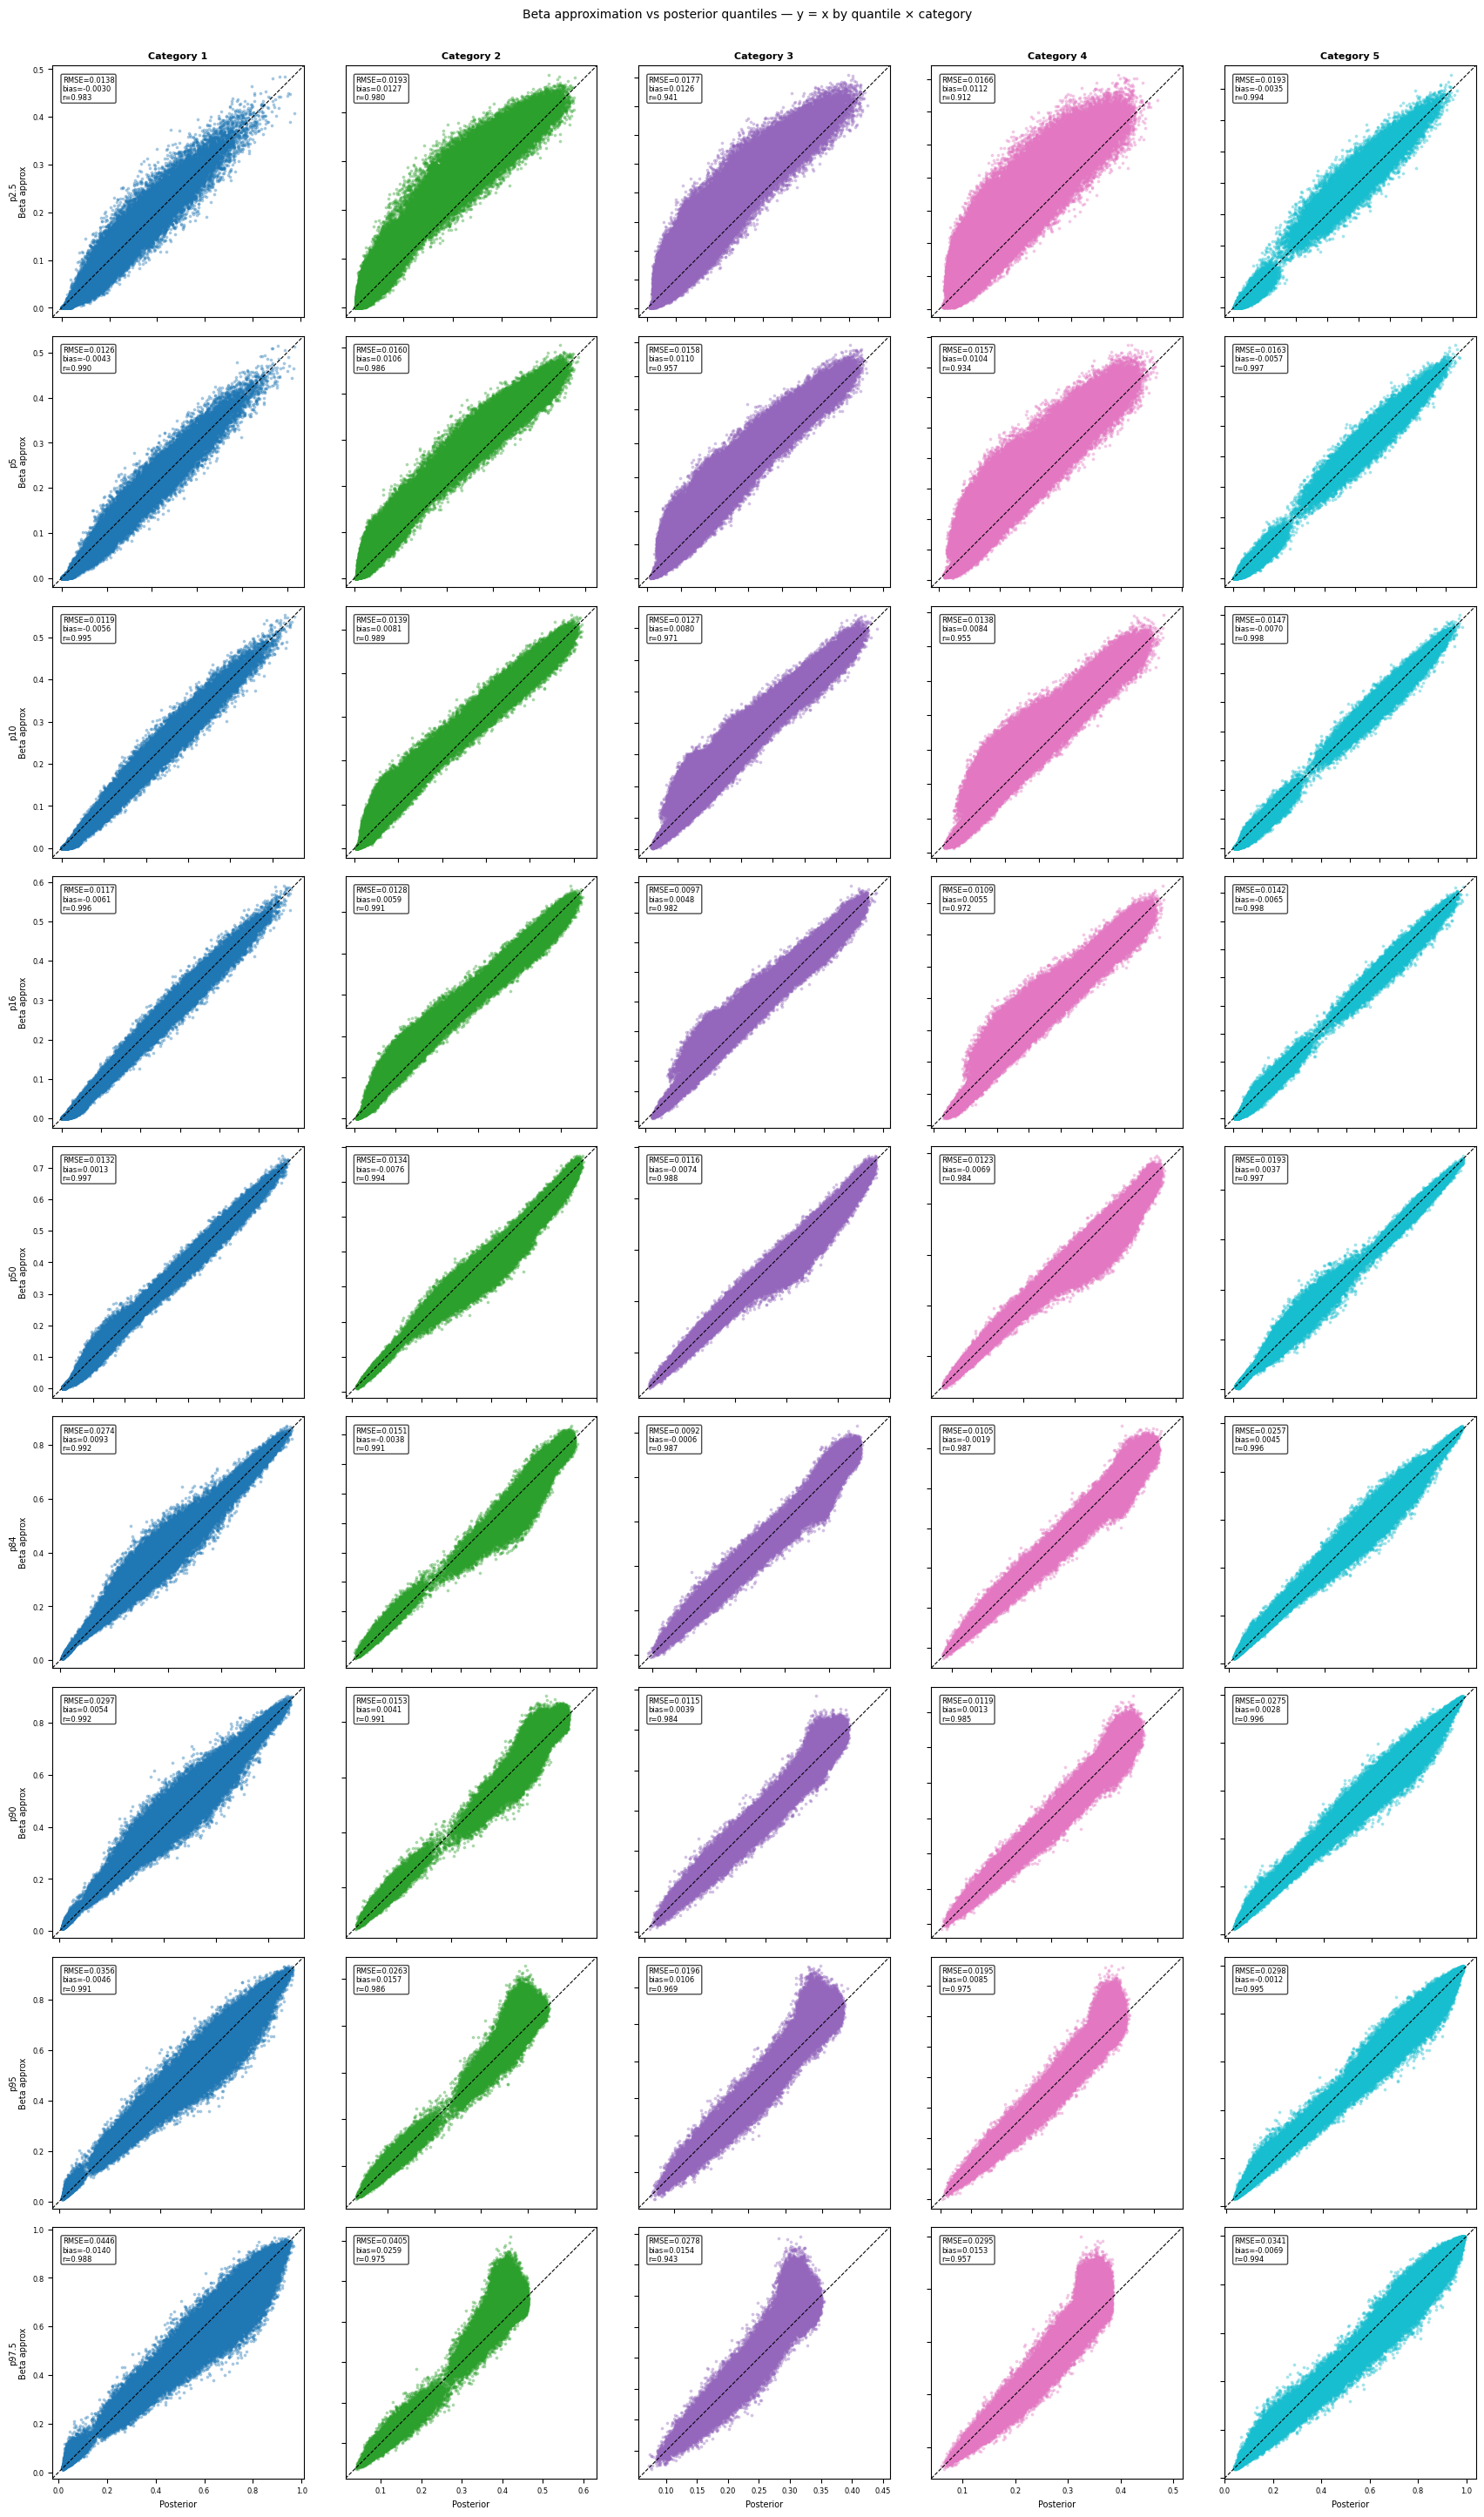

In [24]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

N_BETA_DRAWS = 250

# Percentile and column suffix mapp
QUANT_SPECS = [
    (2.5,  f'{belief_col}_prob_cat_lower_95_'),
    (5,    f'{belief_col}_prob_cat_lower_90_'),
    (10,   f'{belief_col}_prob_cat_lower_80_'),
    (16,   f'{belief_col}_prob_cat_lower_68_'),
    (50,   f'{belief_col}_prob_cat_median_'),
    (84,   f'{belief_col}_prob_cat_upper_68_'),
    (90,   f'{belief_col}_prob_cat_upper_80_'),
    (95,   f'{belief_col}_prob_cat_upper_90_'),
    (97.5, f'{belief_col}_prob_cat_upper_95_'),
]

cat_mean_cols = [c for c in cell_prediction_df.columns if c.startswith(f'{belief_col}_prob_cat_mean_')]
K_cats = sorted(int(c.split('_')[-1]) for c in cat_mean_cols)
print(f"Categories: {K_cats}  |  Quantiles: {[q for q, _ in QUANT_SPECS]}\n")

comparison_rows = []
# plot_data[k][(pct_idx)] = (pct, beta_q, stored_q, stats_dict)
plot_data = {k: [] for k in K_cats}

for k in K_cats:
    mu_k = cell_prediction_df[f'{belief_col}_prob_cat_mean_{k}'].values.astype(float)
    sd_k = cell_prediction_df[f'{belief_col}_prob_cat_sd_{k}'].values.astype(float)
    
    # update draws
    draw_k = []
    # loop through each cell and draw from beta distribution with mean = mu_k and var = sd_k^2
    for i in range(len(mu_k)):
        # append draw_k with N_BETA_DRAWS draws from beta distribution with mean = mu_k[i] and var = sd_k[i]^2
        draw_k_i = rbeta_mean_var(n=N_BETA_DRAWS, mu=mu_k[i], v=sd_k[i]**2)
        draw_k.append(draw_k_i)
    # convert draw_k to dataframe with columns = draw_1, draw_2, ..., draw_250 and rows = n_cells
    draw_k = pd.DataFrame(draw_k, columns=[f'draw_{i+1}' for i in range(N_BETA_DRAWS)])

    for pct, col_prefix in QUANT_SPECS:
        stored_col = f'{col_prefix}{k}'
        if stored_col not in cell_prediction_df.columns:
            continue

        beta_q   = np.percentile(draw_k, pct, axis=1)
        stored_q = cell_prediction_df[stored_col].values.astype(float)

        rmse = np.sqrt(np.mean((beta_q - stored_q) ** 2))
        mae  = np.mean(np.abs(beta_q - stored_q))
        bias = np.mean(beta_q - stored_q)
        corr = np.corrcoef(beta_q, stored_q)[0, 1]

        stats = dict(RMSE=rmse, MAE=mae, bias=bias, corr=corr)
        comparison_rows.append(dict(
            category=k, percentile=pct,
            RMSE=round(rmse, 6), MAE=round(mae, 6),
            bias=round(bias, 6), corr=round(corr, 4),
            mean_beta=round(np.mean(beta_q), 6),
            mean_posterior=round(np.mean(stored_q), 6),
        ))
        plot_data[k].append((pct, beta_q, stored_q, stats))

comparison_df = pd.DataFrame(comparison_rows)
print(comparison_df.to_string(index=False))

# y = x plots: rows = quantiles, columns = categories
n_quants = len(QUANT_SPECS)
n_cats   = len(K_cats)

fig, axes = plt.subplots(
    n_quants, n_cats,
    figsize=(3.5 * n_cats, 3.2 * n_quants),
    squeeze=False
)

# colour per category column
cat_colors = cm.tab10(np.linspace(0, 0.9, n_cats))

for q_idx, (pct, _) in enumerate(QUANT_SPECS):
    for c_idx, k in enumerate(K_cats):
        ax = axes[q_idx][c_idx]

        # find matching entry for this (k, pct)
        entry = next((e for e in plot_data[k] if e[0] == pct), None)
        if entry is None:
            ax.set_visible(False)
            continue

        _, beta_q, stored_q, stats = entry
        color = cat_colors[c_idx]

        ax.scatter(stored_q, beta_q, s=3, alpha=0.3, color=color, rasterized=True)

        lo = min(stored_q.min(), beta_q.min())
        hi = max(stored_q.max(), beta_q.max())
        pad = (hi - lo) * 0.04
        ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], 'k--', lw=0.8)
        ax.set_xlim(lo - pad, hi + pad)
        ax.set_ylim(lo - pad, hi + pad)
        ax.set_aspect('equal', 'box')

        # stats annotation
        label = (
            f"RMSE={stats['RMSE']:.4f}\n"
            f"bias={stats['bias']:.4f}\n"
            f"r={stats['corr']:.3f}"
        )
        ax.text(
            0.04, 0.96, label,
            transform=ax.transAxes,
            fontsize=6, va='top', ha='left',
            bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.7)
        )

        # row label (quantile) on leftmost column
        if c_idx == 0:
            ax.set_ylabel(f'p{pct}\nBeta approx', fontsize=7)
        else:
            ax.set_yticklabels([])

        # column label (category) on top row
        if q_idx == 0:
            ax.set_title(f'Category {k}', fontsize=8, fontweight='bold')

        # x label on bottom row only
        if q_idx == n_quants - 1:
            ax.set_xlabel('Posterior', fontsize=7)
        else:
            ax.set_xticklabels([])

        ax.tick_params(labelsize=6)

fig.suptitle('Beta approximation vs posterior quantiles — y = x by quantile × category',
             fontsize=10, y=1.002)
plt.tight_layout()
plt.show()


In [25]:
comparison_df 

,category,percentile,RMSE,MAE,bias,corr,mean_beta,mean_posterior
0,1,2.5,0.013803,0.008493,-0.002985,0.9825,0.037668,0.040653
1,1,5.0,0.012619,0.008659,-0.004262,0.9903,0.047269,0.051531
2,1,10.0,0.011917,0.008929,-0.005561,0.9947,0.061532,0.067094
3,1,16.0,0.011695,0.009029,-0.006104,0.9964,0.075828,0.081932
4,1,50.0,0.013168,0.009162,0.001302,0.9968,0.159658,0.158356
5,1,84.0,0.027350,0.018623,0.009347,0.9925,0.317589,0.308242
6,1,90.0,0.029734,0.020575,0.005360,0.9918,0.371835,0.366475
7,1,95.0,0.035575,0.024865,-0.004583,0.9905,0.439406,0.443989
8,1,97.5,0.044608,0.031414,-0.014040,0.9884,0.493567,0.507606
9,2,2.5,0.019345,0.014360,0.012719,0.9797,0.069618,0.056900


Categories: [1, 2, 3, 4, 5]  |  Stored draws per category: 250
Row counts OK: 190844 rows across strat_frame, predicted_probability_df, and cell_prediction_df.

Generating beta draws per category ...
  Category 1: done
  Category 2: done
  Category 3: done
  Category 4: done
  Category 5: done

Demographic group columns found: ['sex_idx', 'age_idx', 'eth_idx', 'income_idx', 'vote_idx', 'education_idx', 'state_simple']

Group-level comparison summary:
 category         group  percentile     RMSE      MAE      bias    corr  mean_beta  mean_stored
        1       sex_idx         2.5 0.071106 0.070929  0.070929  1.0000   0.220759     0.149830
        1       sex_idx         5.0 0.063531 0.062942  0.062942  1.0000   0.221198     0.158256
        1       sex_idx        10.0 0.048411 0.048252  0.048252  1.0000   0.221773     0.173521
        1       sex_idx        16.0 0.039369 0.039014  0.039014  1.0000   0.222420     0.183406
        1       sex_idx        50.0 0.003223 0.003142  0.003142  

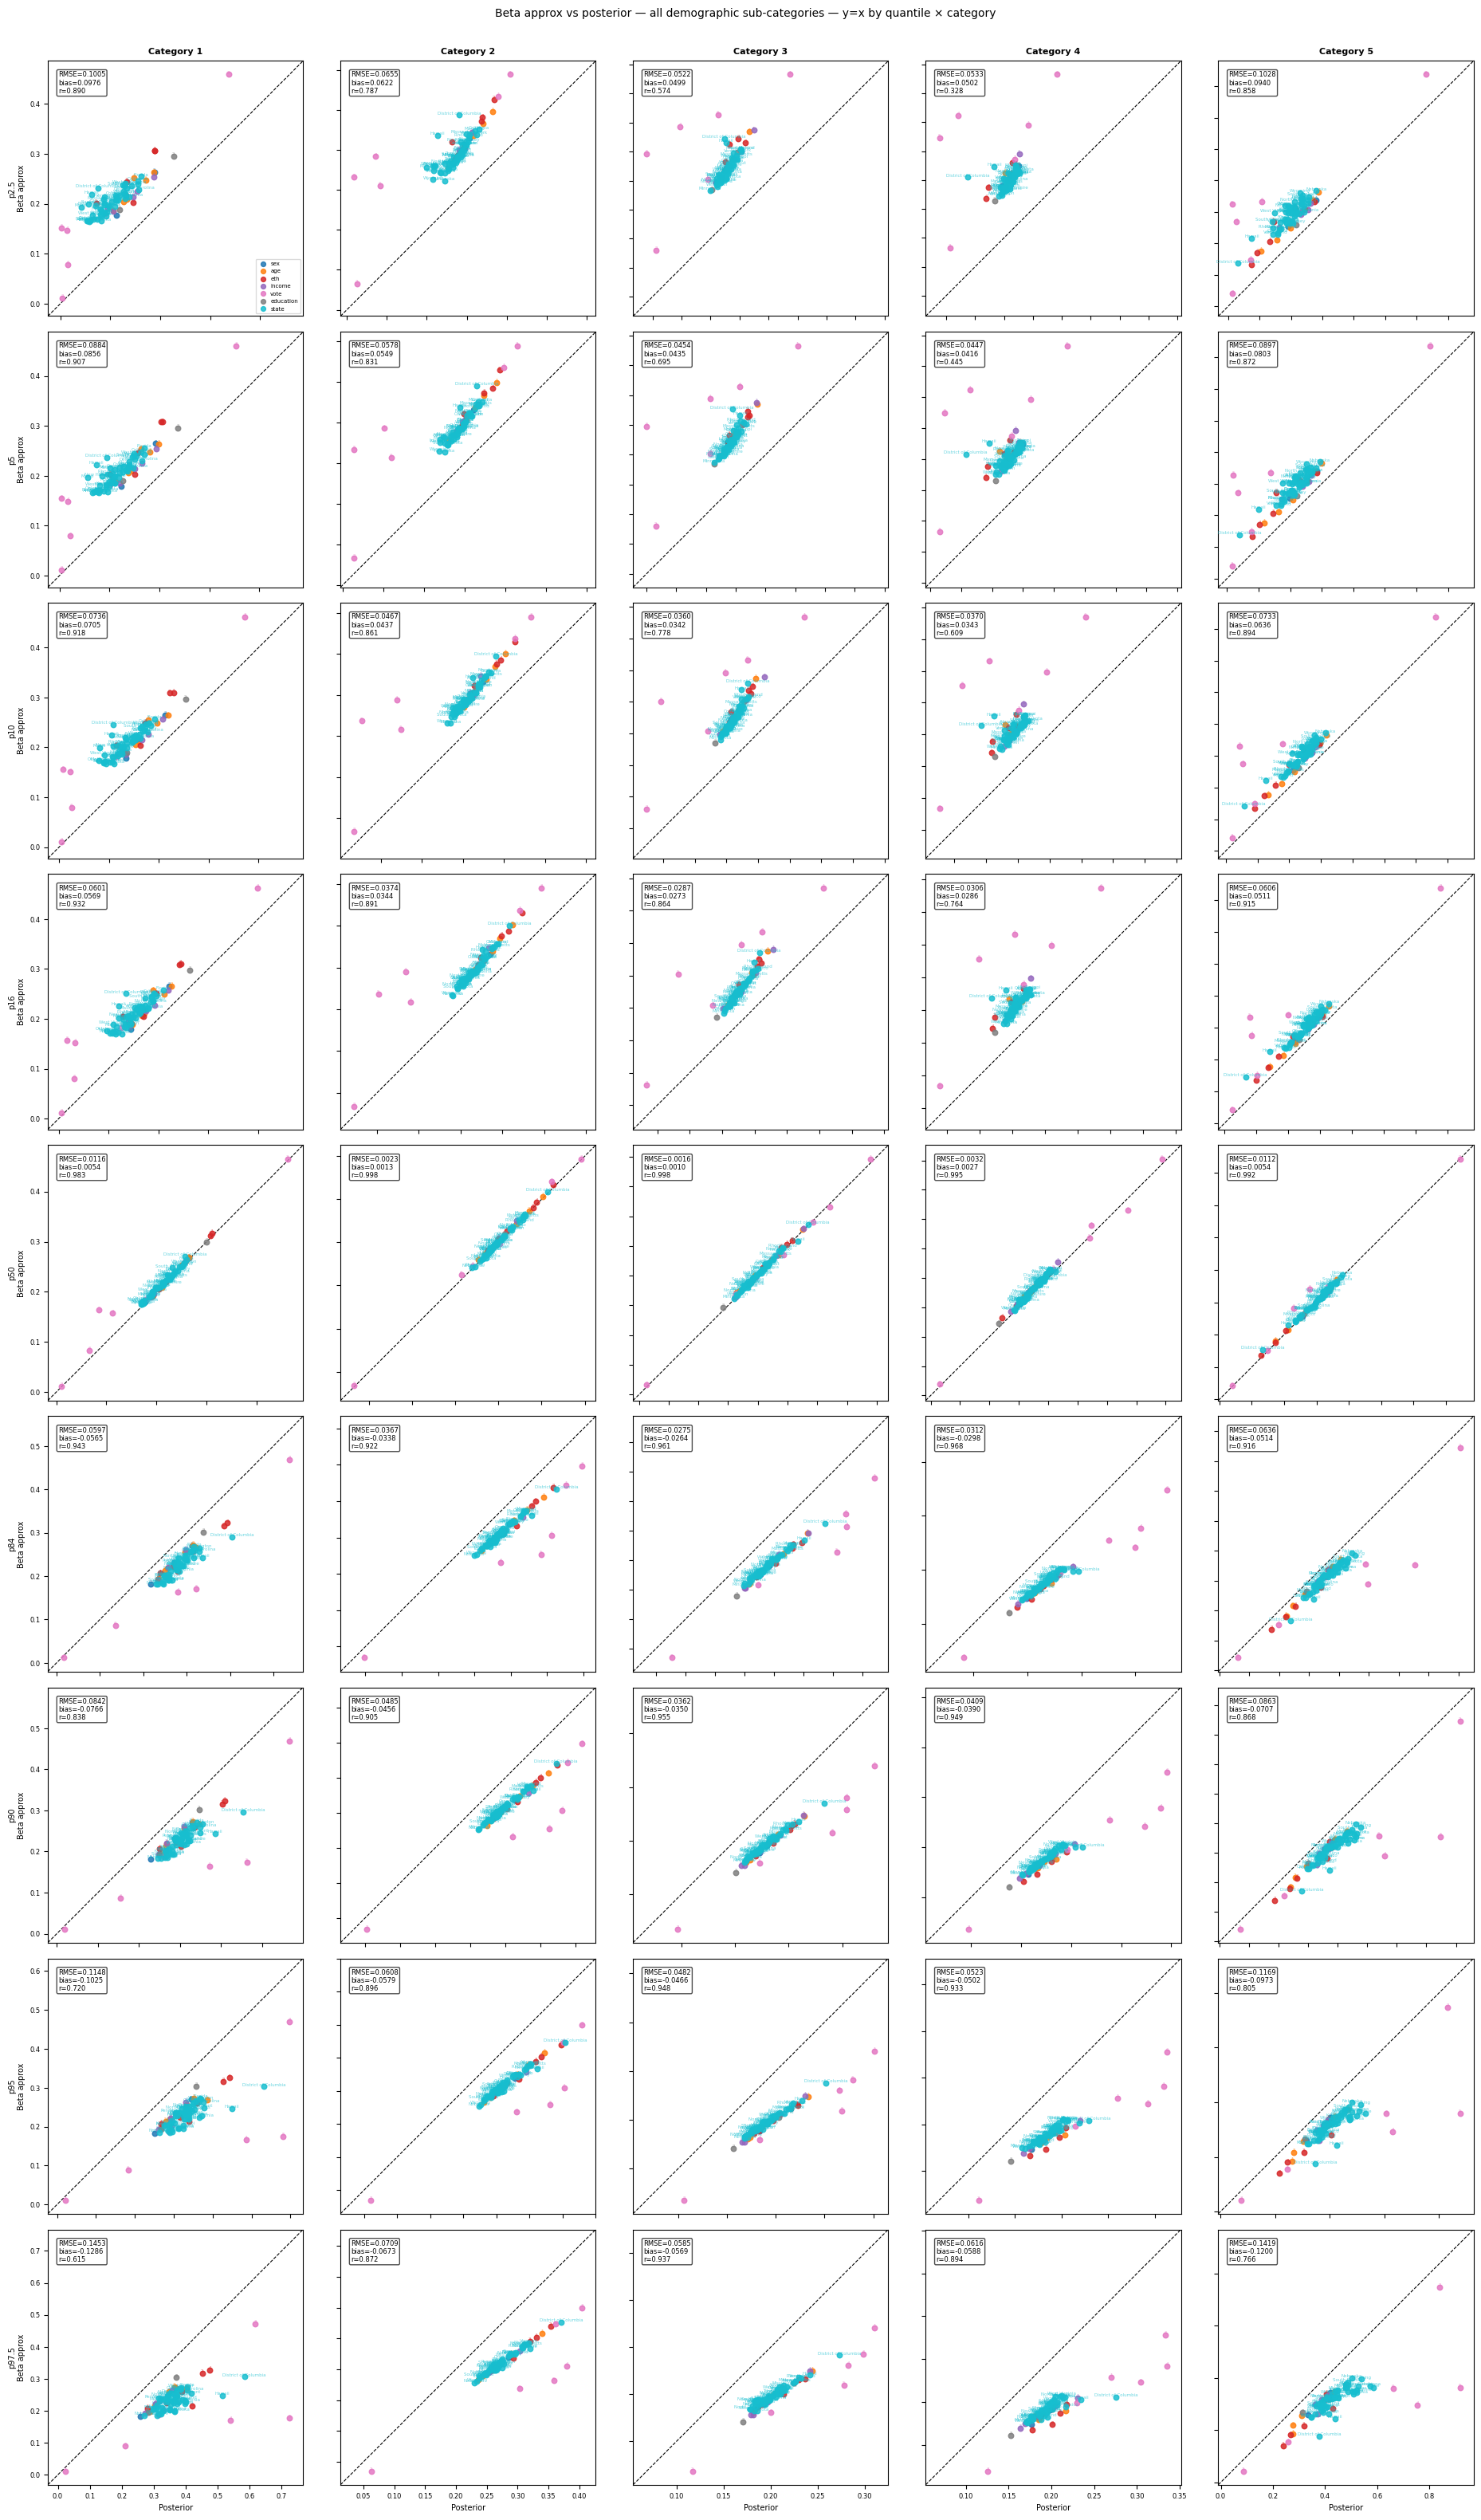

In [ ]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

#  Identify stored draw columns and category count 
cat_draw_pat = re.compile(r'prob_cat_(\d+)_draw_(\d+)')
cat_draw_cols = [c for c in predicted_probability_df.columns if cat_draw_pat.match(c)]
K_cats_grp = sorted(set(int(cat_draw_pat.match(c).group(1)) for c in cat_draw_cols)) # extract unique category numbers (example: 1, 2, 3, 4, 5)
n_draws_stored = max(int(cat_draw_pat.match(c).group(2)) for c in cat_draw_cols)
print(f"Categories: {K_cats_grp}  |  Stored draws per category: {n_draws_stored}")

# check if the stratification frame and the prediction dataframes have the same number of cells
n_strat  = len(strat_frame) # the number of cells in the stratification frame
n_stored = len(predicted_probability_df) # the cell level all draws
n_cell   = len(cell_prediction_df) # the cell level summary stats from the stored draws (mean, median, quantiles)

if n_stored != n_strat:
    raise ValueError(
        f"Row mismatch: predicted_probability_df has {n_stored} rows but "
        f"strat_frame has {n_strat} rows. Stopping."
    )
if n_cell != n_strat:
    raise ValueError(
        f"Row mismatch: cell_prediction_df has {n_cell} rows but "
        f"strat_frame has {n_strat} rows. Stopping."
    )
print(f"Row counts OK: {n_strat} rows across strat_frame, predicted_probability_df, and cell_prediction_df.\n")

#  Generate beta draws (n_cells × N_BETA_DRAWS) per category
beta_draws_by_cat = {} # shape: {k: (n_cells × N_BETA_DRAWS) array of beta draws for category k}
for k in K_cats_grp:
    mu_k = cell_prediction_df[f'{belief_col}_prob_cat_mean_{k}'].values.astype(float)
    sd_k = cell_prediction_df[f'{belief_col}_prob_cat_sd_{k}'].values.astype(float)
    draws_k = np.zeros((n_strat, N_BETA_DRAWS))
    for i in range(n_strat): # loop through all cells
        draws_k[i, :] = rbeta_mean_var(n=N_BETA_DRAWS, mu=mu_k[i], v=sd_k[i]**2) # update the i row of draws_k with N_BETA_DRAWS draws from beta distribution
    beta_draws_by_cat[k] = draws_k

# Stratification metadata
demo_groups_map = {
    'sex':       'sex_idx',
    'age':       'age_idx',
    'eth':       'eth_idx',
    'income':    'income_idx',
    'vote':      'vote_idx',
    'education': 'education_idx',
}
if 'state_simple' in strat_frame.columns:
    demo_groups_map['state'] = 'state_simple'
# elif 'state_idx' in strat_frame.columns:
#     demo_groups_map['state'] = 'state_idx'
else: 
    print("No state column found in strat_frame. State-level grouping will be skipped.")

weights_col = 'N_star.median'
group_cols  = [c for c in demo_groups_map.values() if c in strat_frame.columns] # check which demographic group columns are present in the stratification frame
strat_meta  = strat_frame.reset_index(drop=True)[group_cols + [weights_col]].copy() # extract the demographic group columns and the weight column from the stratification frame
w           = strat_meta[weights_col].values.astype(float) # extract the weight values as a numpy array for later use in weighted aggregation
print(f"\nDemographic group columns found: {group_cols}")

# Weighted group aggregation helper 
def weighted_group_agg(draw_matrix, w, group_labels, unique_groups):
    """
    draw_matrix : (n_cells × n_draws)
    Returns     : (n_groups × n_draws) weighted mean per group
    """
    n_draws = draw_matrix.shape[1] # number of draw columns
    result  = np.zeros((len(unique_groups), n_draws)) # initialize result array to store weighted group means (rows = groups, cols = draws)
    for gi, gval in enumerate(unique_groups): # loop through each unique group value (example: for sex_idx, unique group values might be 1 and 2 representing male and female)
        mask = group_labels == gval # boolean mask to select rows corresponding to the current group value
        w_g  = w[mask] # weights for the current group (only for the cells that belong to this group) (example: if gval is 1 for male, w_g will contain the weights for all male cells)
        d_g  = draw_matrix[mask, :]
        wsum = w_g.sum()
        result[gi, :] = (d_g * w_g[:, np.newaxis]).sum(axis=0) / wsum if wsum > 0 else np.nan
    return result

# Aggregate draws and compute quantiles - collect all groups together
QUANT_LEVELS = [2.5, 5, 10, 16, 50, 84, 90, 95, 97.5]

comparison_rows_grp = []
# plot_data_all[(k, pct)] = list of dicts: {beta_q, stored_q, label, gname}
# one entry per (group × pct × k) but all merged into a flat structure keyed by (k, pct)
plot_data_all = {}

group_colors = cm.tab10(np.linspace(0, 0.9, len(group_cols)))
group_color_map = {gcol: group_colors[i] for i, gcol in enumerate(group_cols)}

for k in K_cats_grp:
    stored_cols_k = [f'prob_cat_{k}_draw_{d+1}' for d in range(n_draws_stored)]
    stored_mat    = predicted_probability_df[stored_cols_k].values.astype(float)
    beta_mat      = beta_draws_by_cat[k]

    for gcol in group_cols:
        gname         = next(name for name, col in demo_groups_map.items() if col == gcol)
        group_labels  = strat_meta[gcol].values
        unique_groups = np.sort(pd.Series(group_labels).dropna().unique())
        n_groups      = len(unique_groups)

        stored_agg = weighted_group_agg(stored_mat, w, group_labels, unique_groups)
        beta_agg   = weighted_group_agg(beta_mat,   w, group_labels, unique_groups)

        for pct in QUANT_LEVELS:
            stored_q = np.percentile(stored_agg, pct, axis=1)
            beta_q   = np.percentile(beta_agg,   pct, axis=1)

            rmse = np.sqrt(np.mean((beta_q - stored_q) ** 2))
            mae  = np.mean(np.abs(beta_q - stored_q))
            bias = np.mean(beta_q - stored_q)
            corr = np.corrcoef(beta_q, stored_q)[0, 1] if n_groups > 1 else np.nan

            comparison_rows_grp.append(dict(
                category=k, group=gcol, percentile=pct,
                RMSE=round(rmse, 6),  MAE=round(mae, 6),
                bias=round(bias, 6),  corr=round(corr, 4),
                mean_beta=round(float(np.mean(beta_q)), 6),
                mean_stored=round(float(np.mean(stored_q)), 6),
            ))

            key = (k, pct)
            plot_data_all.setdefault(key, [])
            for gi, gval in enumerate(unique_groups):
                plot_data_all[key].append({
                    'stored': stored_q[gi],
                    'beta':   beta_q[gi],
                    'label':  f"{gname}:{gval}",
                    'gcol':   gcol,
                    'gname':  gname,
                })

comparison_df_grp = pd.DataFrame(comparison_rows_grp)
print("\nGroup-level comparison summary:")
print(comparison_df_grp.to_string(index=False))

# ── Single grid: rows=quantiles, cols=categories, all demographic dots together ──
n_quants   = len(QUANT_LEVELS)
n_cats     = len(K_cats_grp)
cat_colors = cm.tab10(np.linspace(0, 0.9, n_cats))

fig, axes = plt.subplots(
    n_quants, n_cats,
    figsize=(3.8 * n_cats, 3.5 * n_quants),
    squeeze=False
)

for q_idx, pct in enumerate(QUANT_LEVELS):
    for c_idx, k in enumerate(K_cats_grp):
        ax      = axes[q_idx][c_idx]
        entries = plot_data_all.get((k, pct), [])
        if not entries:
            ax.set_visible(False)
            continue

        all_stored = np.array([e['stored'] for e in entries])
        all_beta   = np.array([e['beta']   for e in entries])

        # Plot each dot coloured by demographic group type
        for gcol in group_cols:
            gname   = next(name for name, col in demo_groups_map.items() if col == gcol)
            g_ents  = [e for e in entries if e['gcol'] == gcol]
            xs      = np.array([e['stored'] for e in g_ents])
            ys      = np.array([e['beta'] for e in g_ents])
            color   = group_color_map[gcol]
            ax.scatter(xs, ys, s=22, alpha=0.85, color=color, label=gname, zorder=3)
            for e in g_ents:
                ax.annotate(
                    str(e['label'].split(':', 1)[1]),
                    (e['stored'], e['beta']),
                    fontsize=4, ha='center', va='bottom', alpha=0.65, color=color
                )

        lo  = min(all_stored.min(), all_beta.min())
        hi  = max(all_stored.max(), all_beta.max())
        pad = max((hi - lo) * 0.06, 1e-4)
        ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], 'k--', lw=0.8)
        ax.set_xlim(lo - pad, hi + pad)
        ax.set_ylim(lo - pad, hi + pad)
        ax.set_aspect('equal', 'box')

        # Summary stats aggregated over all dots in this panel
        rmse_all = float(np.sqrt(np.mean((all_beta - all_stored) ** 2)))
        bias_all = float(np.mean(all_beta - all_stored))
        corr_all = float(np.corrcoef(all_beta, all_stored)[0, 1]) if len(all_stored) > 1 else np.nan
        lbl = f"RMSE={rmse_all:.4f}\nbias={bias_all:.4f}\nr={corr_all:.3f}"
        ax.text(0.04, 0.96, lbl, transform=ax.transAxes,
                fontsize=6, va='top', ha='left',
                bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.7))

        if c_idx == 0:
            ax.set_ylabel(f'p{pct}\nBeta approx', fontsize=7)
        else:
            ax.set_yticklabels([])

        if q_idx == 0:
            ax.set_title(f'Category {k}', fontsize=8, fontweight='bold')

        if q_idx == n_quants - 1:
            ax.set_xlabel('Posterior', fontsize=7)
        else:
            ax.set_xticklabels([])

        ax.tick_params(labelsize=6)

        # Legend only in top-left panel
        if q_idx == 0 and c_idx == 0:
            ax.legend(fontsize=5, markerscale=0.9, loc='lower right',
                      framealpha=0.7, handletextpad=0.3)

fig.suptitle(
    'Beta approx vs posterior — all demographic sub-categories — y=x by quantile × category',
    fontsize=10, y=1.002
)
plt.tight_layout()
plt.show()


In [9]:
cell_prediction_df.columns.to_list()

['Unnamed: 0',
 'sex_idx',
 'age_idx',
 'eth_idx',
 'income_idx',
 'state_idx',
 'vote_idx',
 'education_idx',
 'N_star.1',
 'N_star.2',
 'N_star.3',
 'N_star.4',
 'N_star.5',
 'N_star.6',
 'N_star.7',
 'N_star.8',
 'N_star.9',
 'N_star.10',
 'N_star.11',
 'N_star.12',
 'N_star.13',
 'N_star.14',
 'N_star.15',
 'N_star.16',
 'N_star.17',
 'N_star.18',
 'N_star.19',
 'N_star.20',
 'N_star.21',
 'N_star.22',
 'N_star.23',
 'N_star.24',
 'N_star.25',
 'N_star.26',
 'N_star.27',
 'N_star.28',
 'N_star.29',
 'N_star.30',
 'N_star.31',
 'N_star.32',
 'N_star.33',
 'N_star.34',
 'N_star.35',
 'N_star.36',
 'N_star.37',
 'N_star.38',
 'N_star.39',
 'N_star.40',
 'N_star.41',
 'N_star.42',
 'N_star.43',
 'N_star.44',
 'N_star.45',
 'N_star.46',
 'N_star.47',
 'N_star.48',
 'N_star.49',
 'N_star.50',
 'N_star.51',
 'N_star.52',
 'N_star.53',
 'N_star.54',
 'N_star.55',
 'N_star.56',
 'N_star.57',
 'N_star.58',
 'N_star.59',
 'N_star.60',
 'N_star.61',
 'N_star.62',
 'N_star.63',
 'N_star.64',
 '

In [ ]:
state_group_draws = pd.read_csv("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Order_Immigrant_Education/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_2023-12-03 00:00:00+00:00_stan_output/state_level_all_draws.csv")
state_group_draws #(row = n_states, columns = state + n_draws)

,state_simple,draw_1,draw_2,draw_3,draw_4,draw_5,draw_6,draw_7,draw_8,draw_9,...,draw_491,draw_492,draw_493,draw_494,draw_495,draw_496,draw_497,draw_498,draw_499,draw_500
0,Alabama,4.051822,3.069795,3.123298,3.448920,3.568513,3.289014,3.407227,3.531210,3.101173,...,3.118008,3.413722,3.121532,2.902465,3.177677,2.930186,2.927376,3.336180,3.124768,3.529939
1,Alaska,3.432734,2.787239,3.135293,3.394714,3.749825,3.546461,3.635480,3.479871,3.063196,...,3.214178,3.435282,3.342093,2.909192,3.348232,3.098568,3.011026,3.374806,3.058992,3.185341
2,Arizona,3.179006,3.054045,3.162037,2.737122,2.638025,3.151104,2.884635,3.116678,2.907571,...,3.184290,3.477913,3.134379,2.950692,3.023850,2.982102,2.740074,3.639365,3.099124,3.226910
3,Arkansas,3.952744,2.835593,2.844820,2.768276,3.290100,3.032915,3.216609,3.541857,2.620168,...,2.849671,3.381382,2.939290,2.599252,2.798049,2.594849,2.713126,3.241276,2.581865,3.281576
4,California,2.483462,2.968403,2.953374,2.608985,2.626836,2.685801,2.509189,2.733012,2.521201,...,2.817891,3.003279,3.199764,3.041334,2.801129,2.727895,2.407470,3.480603,3.014284,3.003118
5,Colorado,2.845580,3.166327,3.487741,3.028880,2.814851,3.271706,3.178565,3.004584,3.263878,...,3.440691,3.553310,3.465079,3.165936,3.355087,3.434480,3.233790,3.763146,3.008807,3.141659
6,Connecticut,2.932828,2.833597,2.965402,2.588565,2.895669,3.305342,2.800561,2.918772,2.945816,...,3.051587,2.889872,2.696149,2.418897,2.933673,3.083372,2.893262,3.097836,2.529672,2.925590
7,Delaware,3.215362,3.943979,3.162596,3.840571,3.460295,3.518223,3.306290,3.121033,3.147575,...,3.104534,2.811040,3.334385,2.712739,3.089296,3.205012,2.978268,3.713888,3.047123,3.272515
8,District of Columbia,1.602109,3.161051,2.403919,2.131775,1.988072,1.854688,1.939680,1.864557,1.769637,...,2.039811,1.609094,3.203262,3.064917,2.281020,2.791577,2.386128,2.527990,1.653209,1.844177
9,Florida,3.737111,3.674974,3.412666,3.394332,3.822260,3.838729,3.552371,3.452447,3.351167,...,3.473850,3.621686,3.611221,3.541086,3.415509,3.262819,3.192186,3.665131,3.757511,3.665279


In [3]:
state_prediction = pd.read_csv("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Order_Immigrant_Education/Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_2023-12-03 00:00:00+00:00_stan_output/state_level_predictions.csv")
state_prediction

,state_simple,pred_mean,pred_median,pred_lower_95,pred_upper_95,pred_lower_90,pred_upper_90,pred_lower_80,pred_upper_80,pred_lower_68,pred_upper_68,pred_sd
0,Alabama,3.364820,3.371119,2.839215,3.930688,2.904246,3.845564,3.028405,3.693937,3.092065,3.614321,0.275807
1,Alaska,3.313333,3.334347,2.615010,4.020411,2.718609,3.860600,2.897567,3.699413,3.012701,3.617101,0.340546
2,Arizona,3.196675,3.213749,2.736628,3.635604,2.798825,3.540701,2.908893,3.476852,2.977351,3.396186,0.226951
3,Arkansas,3.093700,3.083024,2.543491,3.751517,2.613458,3.587508,2.703738,3.468550,2.797873,3.387170,0.310802
4,California,2.892827,2.890802,2.486669,3.357259,2.539273,3.274729,2.621652,3.187771,2.670369,3.095014,0.220974
5,Colorado,3.382711,3.383038,2.889834,3.836972,2.966760,3.787967,3.064194,3.691590,3.148177,3.616692,0.242062
6,Connecticut,2.988136,3.005482,2.397403,3.496157,2.478583,3.430668,2.644085,3.300981,2.739620,3.247231,0.272646
7,Delaware,3.244026,3.201769,2.779289,3.890138,2.860847,3.777172,2.939684,3.642350,2.989506,3.484882,0.277195
8,District of Columbia,2.191301,2.137493,1.552119,3.124503,1.601164,2.905926,1.708807,2.711805,1.799095,2.588910,0.403401
9,Florida,3.556887,3.545710,3.157440,4.019934,3.213172,3.932889,3.274070,3.841502,3.342912,3.774508,0.220014


In [5]:
state_time_series = pd.read_csv("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Order_Immigrant_Education/group_state_idx_category_probs_timeseries.csv")
state_time_series #(row = n_states*n_windows, columns = state + category predicted probability)

,state_idx,prob_mean,category,time_window_start
0,1,0.218153,1,2023-11-05 00:00:00+00:00
1,2,0.219140,1,2023-11-05 00:00:00+00:00
2,3,0.179761,1,2023-11-05 00:00:00+00:00
3,4,0.225006,1,2023-11-05 00:00:00+00:00
4,5,0.252102,1,2023-11-05 00:00:00+00:00
...,...,...,...,...
6625,47,0.277684,5,2024-10-20 00:00:00+00:00
6626,48,0.334485,5,2024-10-20 00:00:00+00:00
6627,49,0.402172,5,2024-10-20 00:00:00+00:00
6628,50,0.354402,5,2024-10-20 00:00:00+00:00


In [ ]:
import pickle
import pandas as pd
import numpy as np
import os

# compute group-level category probabilities from cell-level predictions
def compute_group_category_probabilities(pred_df, belief_col, group_col):
    """
    - For each weight draw, compute weighted group category probabilities
    - Average results across all 104 weight draws
    """
    cat_cols = [c for c in pred_df.columns if c.startswith(f"{belief_col}_prob_cat_mean_")]
    K = max(sorted(int(c.split('_')[-1]) for c in cat_cols)) #number of categories

    n_star_cols = [c for c in pred_df.columns if c.startswith('N_star.')]
    n_star_draws = sorted([c for c in n_star_cols if re.match(r'N_star\.\d+$', c)])
    
    # Randomly sample one weight for each category
    weight_indices = np.random.choice(len(n_star_draws), size=K)
    selected_weights = [n_star_draws[idx] for idx in weight_indices]
    
    # Compute weighted means per category using randomly selected weights
    out_rows = []
    for k in range(1, K+1):
        col_k = f"{belief_col}_prob_cat_mean_{k}"
        if col_k not in pred_df.columns:
            continue
        
        # Use randomly selected weight for this category
        w_col = selected_weights[k-1]
        w = pred_df[w_col].astype(float)
        
        # Compute weighted aggregation
        num_by_group = (pred_df[col_k] * w).groupby(pred_df[group_col]).sum()
        denom_by_group = w.groupby(pred_df[group_col]).sum()
        prob_by_group = (num_by_group / denom_by_group).reset_index()
        prob_by_group.columns = [group_col, 'prob_mean']
        prob_by_group['category'] = k
        out_rows.append(prob_by_group)
    
    if not out_rows:
        raise ValueError(f"No results generated during aggregation. Check that belief column '{belief_col}' and weight columns are present in pred_df.")
    
    final_result = pd.concat(out_rows, ignore_index=True)
    
    return final_result # (row = n_groups * K, columns = group_col, category, prob_mean)

strat_frame = pd.read_csv("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/cleaned_sf.csv")

# Get the time windows from fitted models
base_dir = "/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Order_Immigrant_Education"

# Find all time window directories
time_window_dirs = [d for d in os.listdir(base_dir) if d.startswith(belief_col)]
time_windows = sorted([d.replace(f"{belief_col}_", "").replace("_stan_output", "") for d in time_window_dirs])

print(f"Found {len(time_windows)} time windows: {time_windows}\n")

# Group mapping for consolidation
group_map = [
    ('state_simple', 'state'),
    ('state_idx', 'state_idx'),
    ('sex_idx', 'sex'),
    ('age_idx', 'age'),
    ('eth_idx', 'eth'),
    ('income_idx', 'income'),
    ('vote_idx', 'vote'),
    ('education_idx', 'education')
]

# Initialize storage for consolidated category probabilities across all windows
consolidated_cat_probs = {name: [] for _, name in group_map}

# columns needed only for downstream aggregation / weighting
n_star_cols = [c for c in strat_frame.columns if c.startswith('N_star.')]
n_star_draws = sorted([c for c in n_star_cols if re.match(r'N_star\.\d+$', c)])
merge_cols = ['state_simple', 'state_idx', 'sex_idx', 'age_idx', 'eth_idx', 'income_idx', 'vote_idx', 'education_idx']
merge_cols = [c for c in merge_cols if c in strat_frame.columns]
meta_cols = ['N_star.median'] + merge_cols if 'N_star.median' in strat_frame.columns else merge_cols
meta_cols = n_star_draws + meta_cols

# Loop over each time window
for idx, window in enumerate(time_windows):
    print(f"[{idx+1}/{len(time_windows)}] Processing predictions for window: {window}")
    
    # Load the fitted model for this window
    model_dir = f"{base_dir}/{belief_col}_{window}_stan_output"
    fit_path = f"{model_dir}/fit.pkl"
    
    if not os.path.exists(fit_path):
        print(f"  Warning: fit.pkl not found for window {window}")
        continue
    
    try:
        with open(fit_path, "rb") as f:
            fit = pickle.load(f)
        
        # Generate cell-level predictions (update: no copied stratification columns)
        strat_frame_copy = strat_frame.copy()
        prediction_summary_df, expected_value_draws_df, prob_category_draws_df, K, draw_indices = generate_cell_level_predictions(
            fit,
            strat_frame_copy,
            belief_col,
            batch_size=10000,
            n_keep_draws=250
        )

        # Strict guard: stratification rows must exactly match generated cell-level rows
        n_cells_expected = len(strat_frame_copy)
        if (
            len(prediction_summary_df) != n_cells_expected
            or len(expected_value_draws_df) != n_cells_expected
            or len(prob_category_draws_df) != n_cells_expected
        ):
            warning_msg = (
                "WARNING: Length mismatch detected between stratification frame and cell-level outputs. "
                "Stopping execution with no fallback."
            )
            print(warning_msg)
            raise ValueError(warning_msg)

        # Save compact cell-level outputs
        prediction_summary_df.to_csv(f"{model_dir}/cell_level_predictions.csv", index=False)
        # expected_value_draws_df.to_csv(f"{model_dir}/cell_level_expected_value_draws.csv", index=False)
        # prob_category_draws_df.to_csv(f"{model_dir}/cell_level_category_probability_draws.csv.gz", index=False, compression='gzip')

        # Save selected draw indices
        pd.Series(draw_indices, name='draw_index').to_csv(f"{model_dir}/selected_draw_indices.csv", index=False)

        # # Save kappa draws corresponding to selected draw indices
        # try:
        #     kappa_full = fit.stan_variable('kappa')
        #     kappa_sub = kappa_full[draw_indices, :]
        #     kappa_sub_df = pd.DataFrame(kappa_sub, columns=[f'kappa_{i+1}' for i in range(kappa_sub.shape[1])])
        #     kappa_sub_df.to_csv(f"{model_dir}/kappa_subsampled.csv", index=False)
        # except Exception as e:
        #     print(f"Warning: failed to save kappa subsample: {e}")

        # Build merge-ready metadata frame (stable key + original order)
        merge_meta = strat_frame_copy.reset_index(drop=True).loc[:, meta_cols].copy()
        merge_meta.insert(0, 'cell_id', np.arange(len(merge_meta), dtype=int))

        # Temporary frames for weighted aggregation only
        draws_for_agg = expected_value_draws_df.merge(merge_meta, on='cell_id', how='left')
        pred_for_agg = prediction_summary_df.merge(merge_meta, on='cell_id', how='left')

        # State-level aggregation and save (expected value draws)
        state_group_col = 'state_simple' if 'state_simple' in draws_for_agg.columns else ('state_idx' if 'state_idx' in draws_for_agg.columns else None)
        if state_group_col is not None:
            state_all_draws = aggregate_draws_by_group(draws_for_agg, state_group_col)
            state_preds = summarize_group_draws(state_all_draws, state_group_col)
            state_all_draws.to_csv(f"{model_dir}/state_level_all_draws.csv", index=False)
            state_preds.to_csv(f"{model_dir}/state_level_predictions.csv", index=False)
        else:
            print("Warning: no state column found; skipping state-level aggregation.")

        # Demographic group aggregations and save (expected value draws)
        demo_group_map = [
            ('sex_idx', 'sex'),
            ('age_idx', 'age'),
            ('eth_idx', 'eth'),
            ('income_idx', 'income'),
            ('vote_idx', 'vote'),
            ('education_idx', 'education')
        ]
        for gcol, gname in demo_group_map:
            if gcol in draws_for_agg.columns:
                grp_draws = aggregate_draws_by_group(draws_for_agg, gcol)
                grp_preds = summarize_group_draws(grp_draws, gcol)
                grp_draws.to_csv(f"{model_dir}/group_{gname}_all_draws.csv", index=False)
                grp_preds.to_csv(f"{model_dir}/group_{gname}_predictions.csv", index=False)
            else:
                print(f"Note: column '{gcol}' not found; skipping group '{gname}'.")
        
        # Compute category probabilities for all groups and store for consolidation
        print(f"  Computing category probabilities using all 104 weight samples...")
        for gcol, gname in group_map:
            if gcol not in pred_for_agg.columns:
                continue
            try:
                grp_cat = compute_group_category_probabilities(
                    pred_for_agg, belief_col, gcol
                )
                grp_cat['time_window_start'] = window
                consolidated_cat_probs[gname].append(grp_cat)
            except Exception as e:
                print(f"    Warning: failed to compute {gname} category probs: {e}")
        
        print(f"  Successfully generated all predictions for window {window}\n")
        
    except Exception as e:
        if "Length mismatch detected between stratification frame and cell-level outputs" in str(e):
            raise
        print(f"  Failed to process window {window}: {e}\n")
        continue

print("All time windows processed!")

# Save consolidated category probability timeseries files
print("\nSaving consolidated category probability timeseries...")
for gname, parts in consolidated_cat_probs.items():
    if parts:
        df_all = pd.concat(parts, ignore_index=True)
        output_path = f"{base_dir}/group_{gname}_category_probs_timeseries.csv"
        df_all.to_csv(output_path, index=False)
        print(f" Saved {gname}: {df_all.shape[0]} rows, {df_all['time_window_start'].nunique()} windows")
    else:
        print(f" No data for {gname}")

print("\nPrediction and consolidation pipeline complete!")

Found 26 time windows: ['2023-11-05 00:00:00+00:00', '2023-11-19 00:00:00+00:00', '2023-12-03 00:00:00+00:00', '2023-12-17 00:00:00+00:00', '2023-12-31 00:00:00+00:00', '2024-01-14 00:00:00+00:00', '2024-01-28 00:00:00+00:00', '2024-02-11 00:00:00+00:00', '2024-02-25 00:00:00+00:00', '2024-03-10 00:00:00+00:00', '2024-03-24 00:00:00+00:00', '2024-04-07 00:00:00+00:00', '2024-04-21 00:00:00+00:00', '2024-05-05 00:00:00+00:00', '2024-05-19 00:00:00+00:00', '2024-06-02 00:00:00+00:00', '2024-06-16 00:00:00+00:00', '2024-06-30 00:00:00+00:00', '2024-07-14 00:00:00+00:00', '2024-07-28 00:00:00+00:00', '2024-08-11 00:00:00+00:00', '2024-08-25 00:00:00+00:00', '2024-09-08 00:00:00+00:00', '2024-09-22 00:00:00+00:00', '2024-10-06 00:00:00+00:00', '2024-10-20 00:00:00+00:00']

[1/26] Processing predictions for window: 2023-11-05 00:00:00+00:00
Subsampling draws: using 500 out of 8000 posterior draws

Generating predictions for 220,320 cells in 23 batches of size 10000
Using 104 posterior weight